# 📘 0. Introduction

This notebook presents a complete, exam-ready machine learning workflow for a transportation analytics setting. The work addresses four related tasks:

1. **Data understanding and preprocessing**
2. **Traffic pattern discovery using clustering**
3. **Traffic condition classification**
4. **Traffic flow prediction using regression**

The datasets are assumed to be available in the Google Colab working directory:

- `transport_clustering_train.csv`
- `transport_clustering_test.csv`
- `transport_classification_train.csv`
- `transport_classification_test.csv`
- `transport_regression_train.csv`
- `transport_regression_test.csv`

## Why preprocessing is critical in transportation systems

Transportation data is often noisy, heterogeneous, and operationally messy. It may include:
- sensor errors and missing values,
- extreme events that create outliers,
- mixed numeric and categorical variables,
- highly correlated measurements (for example, speed, density, and flow-related attributes),
- identifiers that carry no predictive meaning.

If preprocessing is handled poorly, model performance becomes unreliable and evaluation becomes misleading. For that reason, this notebook uses **leakage-safe preprocessing**, meaning that all transformations are **fit only on training data** and then applied to validation/test data. This is especially important in traffic modeling, where deployment decisions can affect congestion control, route guidance, and operational planning.

In [18]:
!pip install seaborn

In [19]:

# Core libraries
import warnings
warnings.filterwarnings("ignore")

import os
import math
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

# Preprocessing and modeling
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats.mstats import winsorize

sns.set(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

In [20]:

# File paths (Google Colab / current working directory)
DATA_FILES = {
    "clustering_train": "transport_clustering_train.csv",
    "clustering_test": "transport_clustering_test.csv",
    "classification_train": "transport_classification_train.csv",
    "classification_test": "transport_classification_test.csv",
    "regression_train": "transport_regression_train.csv",
    "regression_test": "transport_regression_test.csv",
}

missing_files = [path for path in DATA_FILES.values() if not os.path.exists(path)]
if missing_files:
    raise FileNotFoundError(
        "The following required CSV files were not found in the current directory:\n"
        + "\n".join(missing_files)
        + "\n\nUpload them to Colab or place them in the notebook working directory."
    )

print("All required datasets were found successfully.")

All required datasets were found successfully.


# 📘 1. Problem 1 — Data Understanding and Preprocessing

## 1.1 Load and Inspect Data

We start by loading **all training datasets** and the corresponding test sets for later use. At this stage, the goal is to understand:
- the dimensionality of each dataset,
- the variable types,
- the likely target column for supervised tasks,
- whether potential identifier columns exist.

This step is important because preprocessing decisions should be grounded in the actual structure of the data rather than assumptions.

In [21]:

# Load datasets
df_cluster_train = pd.read_csv(DATA_FILES["clustering_train"])
df_cluster_test = pd.read_csv(DATA_FILES["clustering_test"])

df_class_train = pd.read_csv(DATA_FILES["classification_train"])
df_class_test = pd.read_csv(DATA_FILES["classification_test"])

df_reg_train = pd.read_csv(DATA_FILES["regression_train"])
df_reg_test = pd.read_csv(DATA_FILES["regression_test"])

datasets = {
    "Clustering Train": df_cluster_train,
    "Clustering Test": df_cluster_test,
    "Classification Train": df_class_train,
    "Classification Test": df_class_test,
    "Regression Train": df_reg_train,
    "Regression Test": df_reg_test,
}

for name, df in datasets.items():
    print("=" * 100)
    print(name)
    print("- Shape:", df.shape)
    print("- Columns:", list(df.columns))
    print("- Data types:")
    display(df.dtypes.to_frame("dtype"))
    print("- First 5 rows:")
    display(df.head())

Clustering Train
- Shape: (1200, 12)
- Columns: ['record_id', 'hour_of_day', 'road_type', 'lane_count', 'avg_speed_kph', 'traffic_flow_vehph', 'occupancy_pct', 'queue_length_m', 'precipitation_mm', 'incident_flag', 'signal_density_per_km', 'device_batch']
- Data types:


,dtype
record_id,int64
hour_of_day,int64
road_type,object
lane_count,int64
avg_speed_kph,float64
traffic_flow_vehph,float64
occupancy_pct,float64
queue_length_m,float64
precipitation_mm,float64
incident_flag,int64


- First 5 rows:


,record_id,hour_of_day,road_type,lane_count,avg_speed_kph,traffic_flow_vehph,occupancy_pct,queue_length_m,precipitation_mm,incident_flag,signal_density_per_km,device_batch
0,1,17,Arterial,2,66.2,1100.3,18.0,10.9,0.41,0,3.23,B3
1,2,13,Collector,3,73.7,1176.6,22.9,0.0,0.00,0,5.20,B1
2,3,19,Collector,4,20.9,1253.2,71.5,199.1,3.22,0,4.83,B1
3,4,4,Collector,3,28.9,2218.9,66.5,259.9,1.54,0,5.58,B2
4,5,20,Collector,4,15.8,1190.8,87.3,246.0,NaN,1,4.97,B3


Clustering Test
- Shape: (420, 12)
- Columns: ['record_id', 'hour_of_day', 'road_type', 'lane_count', 'avg_speed_kph', 'traffic_flow_vehph', 'occupancy_pct', 'queue_length_m', 'precipitation_mm', 'incident_flag', 'signal_density_per_km', 'device_batch']
- Data types:


...

,record_id,road_type,hour_of_day,route_length_km,distance_km,weather_state,precipitation_mm,signal_density_per_km,bus_stop_density_per_km,incident_flag,demand_index,avg_speed_kph,navigation_eta_minutes,driver_experience_level,travel_time_minutes
0,1,Arterial,12,13.19,13.35,Clear,0.00,2.41,2.44,0,1.01,47.4,16.63,Low,23.43
1,2,Collector,4,4.86,4.84,Cloudy,0.42,4.05,4.00,0,0.82,24.4,13.26,High,21.48
2,3,Highway,12,18.64,17.60,Clear,0.02,0.40,0.26,1,0.80,72.6,13.07,Medium,23.79
3,4,Arterial,4,10.93,10.92,Clear,0.02,3.18,4.14,0,0.95,44.0,13.98,Low,22.10
4,5,Highway,22,13.58,12.02,Clear,0.00,0.40,0.10,0,0.75,72.5,12.66,Medium,11.07


Regression Test
- Shape: (520, 15)
- Columns: ['record_id', 'road_type', 'hour_of_day', 'route_length_km', 'distance_km', 'weather_state', 'precipitation_mm', 'signal_density_per_km', 'bus_stop_density_per_km', 'incident_flag', 'demand_index', 'avg_speed_kph', 'navigation_eta_minutes', 'driver_experience_level', 'travel_time_minutes']
- Data types:


,dtype
record_id,int64
road_type,object
hour_of_day,int64
route_length_km,float64
distance_km,float64
weather_state,object
precipitation_mm,float64
signal_density_per_km,float64
bus_stop_density_per_km,float64
incident_flag,int64


- First 5 rows:


,record_id,road_type,hour_of_day,route_length_km,distance_km,weather_state,precipitation_mm,signal_density_per_km,bus_stop_density_per_km,incident_flag,demand_index,avg_speed_kph,navigation_eta_minutes,driver_experience_level,travel_time_minutes
0,1,Collector,9,11.05,11.71,Rain,3.46,3.94,3.32,1,1.62,7.3,96.66,Medium,110.38
1,2,Arterial,11,5.37,5.45,Rain,2.07,3.25,2.74,0,1.12,35.7,9.79,High,16.99
2,3,Highway,15,16.71,15.51,Cloudy,0.06,0.40,1.14,0,1.26,51.2,19.39,Low,23.45
3,4,Highway,4,17.68,16.44,Rain,3.40,0.40,0.10,0,0.68,78.2,14.10,Low,21.34
4,5,Collector,19,7.12,6.87,Cloudy,0.16,5.33,3.76,0,1.42,NaN,17.35,High,26.42


In [22]:

# Focused inspection of the three training datasets required in Problem 1
training_datasets = {
    "Clustering Train": df_cluster_train,
    "Classification Train": df_class_train,
    "Regression Train": df_reg_train,
}

for name, df in training_datasets.items():
    print("=" * 100)
    print(f"{name} | shape = {df.shape}")
    display(df.head())

Clustering Train | shape = (1200, 12)


,record_id,hour_of_day,road_type,lane_count,avg_speed_kph,traffic_flow_vehph,occupancy_pct,queue_length_m,precipitation_mm,incident_flag,signal_density_per_km,device_batch
0,1,17,Arterial,2,66.2,1100.3,18.0,10.9,0.41,0,3.23,B3
1,2,13,Collector,3,73.7,1176.6,22.9,0.0,0.00,0,5.20,B1
2,3,19,Collector,4,20.9,1253.2,71.5,199.1,3.22,0,4.83,B1
3,4,4,Collector,3,28.9,2218.9,66.5,259.9,1.54,0,5.58,B2
4,5,20,Collector,4,15.8,1190.8,87.3,246.0,NaN,1,4.97,B3


Classification Train | shape = (1800, 18)


,record_id,road_type,zone_type,hour_of_day,lane_count,weather_state,precipitation_mm,visibility_km,incident_flag,special_event_flag,signal_density_per_km,avg_speed_kph,traffic_flow_vehph,upstream_flow_vehph,queue_length_m,sensor_quality_score,firmware_version,delay_risk_class
0,1,Arterial,CBD,11,3,Rain,4.31,3.79,0,0,3.68,NaN,978.2,851.5,116.4,0.92,2.1,Medium
1,2,Highway,CBD,18,2,Clear,0.00,9.61,0,0,1.76,NaN,1020.7,1053.9,115.2,0.98,2.0,Medium
2,3,Highway,Suburban,15,3,Storm,12.45,1.42,0,0,0.72,23.6,659.7,680.5,211.6,0.92,2.1,High
3,4,Highway,Industrial,17,3,Clear,0.00,9.19,0,0,0.50,79.3,1242.5,1248.5,38.3,0.89,2.1,Low
4,5,Arterial,Suburban,18,2,Clear,0.03,10.19,0,0,4.42,41.8,845.8,976.9,59.3,0.89,2.1,Low


Regression Train | shape = (1600, 15)


,record_id,road_type,hour_of_day,route_length_km,distance_km,weather_state,precipitation_mm,signal_density_per_km,bus_stop_density_per_km,incident_flag,demand_index,avg_speed_kph,navigation_eta_minutes,driver_experience_level,travel_time_minutes
0,1,Arterial,12,13.19,13.35,Clear,0.00,2.41,2.44,0,1.01,47.4,16.63,Low,23.43
1,2,Collector,4,4.86,4.84,Cloudy,0.42,4.05,4.00,0,0.82,24.4,13.26,High,21.48
2,3,Highway,12,18.64,17.60,Clear,0.02,0.40,0.26,1,0.80,72.6,13.07,Medium,23.79
3,4,Arterial,4,10.93,10.92,Clear,0.02,3.18,4.14,0,0.95,44.0,13.98,Low,22.10
4,5,Highway,22,13.58,12.02,Clear,0.00,0.40,0.10,0,0.75,72.5,12.66,Medium,11.07


## 1.2 Exploratory Data Analysis (EDA)

EDA serves two purposes here:

1. It helps us understand the **distributional behavior** of transportation variables.
2. It provides evidence for downstream preprocessing choices such as scaling, outlier treatment, and encoding.

For each training dataset, we will examine:
- summary statistics,
- histograms for numerical features,
- count plots for categorical features,
- boxplots for outlier inspection,
- correlation heatmaps.

This is especially relevant in transportation applications because traffic variables often have skewness, operational limits, and strong interdependence.

In [23]:

def split_feature_types(df):
    """Return numeric and categorical column lists based on pandas dtypes."""
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
    return numeric_cols, categorical_cols


def plot_histograms(df, title_prefix="", max_cols_per_row=3):
    numeric_cols, _ = split_feature_types(df)
    if not numeric_cols:
        print(f"No numeric columns available for histograms in {title_prefix}.")
        return

    n = len(numeric_cols)
    rows = math.ceil(n / max_cols_per_row)
    fig, axes = plt.subplots(rows, max_cols_per_row, figsize=(6 * max_cols_per_row, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, numeric_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=ax)
        ax.set_title(f"{title_prefix} - Histogram: {col}")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def plot_countplots(df, title_prefix="", max_cols=8):
    _, categorical_cols = split_feature_types(df)
    if not categorical_cols:
        print(f"No categorical columns available for count plots in {title_prefix}.")
        return

    for col in categorical_cols[:max_cols]:
        plt.figure(figsize=(8, 4))
        order = df[col].astype(str).value_counts().index
        sns.countplot(data=df, x=df[col].astype(str), order=order)
        plt.title(f"{title_prefix} - Count Plot: {col}")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()


def plot_boxplots(df, title_prefix="", max_cols_per_row=3):
    numeric_cols, _ = split_feature_types(df)
    if not numeric_cols:
        print(f"No numeric columns available for boxplots in {title_prefix}.")
        return

    n = len(numeric_cols)
    rows = math.ceil(n / max_cols_per_row)
    fig, axes = plt.subplots(rows, max_cols_per_row, figsize=(6 * max_cols_per_row, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, numeric_cols):
        sns.boxplot(x=df[col], ax=ax)
        ax.set_title(f"{title_prefix} - Boxplot: {col}")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def plot_correlation_heatmap(df, title_prefix=""):
    numeric_cols, _ = split_feature_types(df)
    if len(numeric_cols) < 2:
        print(f"Not enough numeric columns for correlation heatmap in {title_prefix}.")
        return

    corr = df[numeric_cols].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
    plt.title(f"{title_prefix} - Correlation Heatmap")
    plt.tight_layout()
    plt.show()


def perform_eda(df, dataset_name):
    print("=" * 100)
    print(f"EDA for {dataset_name}")
    print("\nSummary statistics (numerical):")
    display(df.describe(include=[np.number]).T)

    print("\nSummary statistics (categorical):")
    try:
        display(df.describe(include=["object", "category", "bool"]).T)
    except Exception:
        print("No categorical summary available.")

    plot_histograms(df, dataset_name)
    plot_countplots(df, dataset_name)
    plot_boxplots(df, dataset_name)
    plot_correlation_heatmap(df, dataset_name)

EDA for Clustering Train

Summary statistics (numerical):


,count,mean,std,min,25%,50%,75%,max
record_id,1200.0,600.500000,346.554469,1.0,300.7500,600.50,900.2500,1200.00
hour_of_day,1200.0,12.084167,4.764557,2.0,8.0000,12.00,16.0000,23.00
lane_count,1200.0,3.256667,0.964312,2.0,2.0000,3.00,4.0000,5.00
avg_speed_kph,1140.0,50.795263,24.681621,5.0,30.0750,46.20,72.6250,165.40
traffic_flow_vehph,1200.0,1444.112667,379.475310,641.7,1148.1750,1375.55,1731.5250,2651.80
occupancy_pct,1152.0,49.332031,27.141691,3.0,21.6500,58.80,72.0000,99.00
queue_length_m,1200.0,209.785583,243.327547,0.0,33.3750,186.40,326.9250,3070.80
precipitation_mm,1128.0,1.161959,1.899286,0.0,0.1700,0.43,0.9725,9.34
incident_flag,1200.0,0.137500,0.344518,0.0,0.0000,0.00,0.0000,1.00
signal_density_per_km,1200.0,3.419858,1.769712,0.4,1.8975,3.80,4.6925,7.90



Summary statistics (categorical):


,count,unique,top,freq
road_type,1200,3,Arterial,583
device_batch,1200,3,B2,416


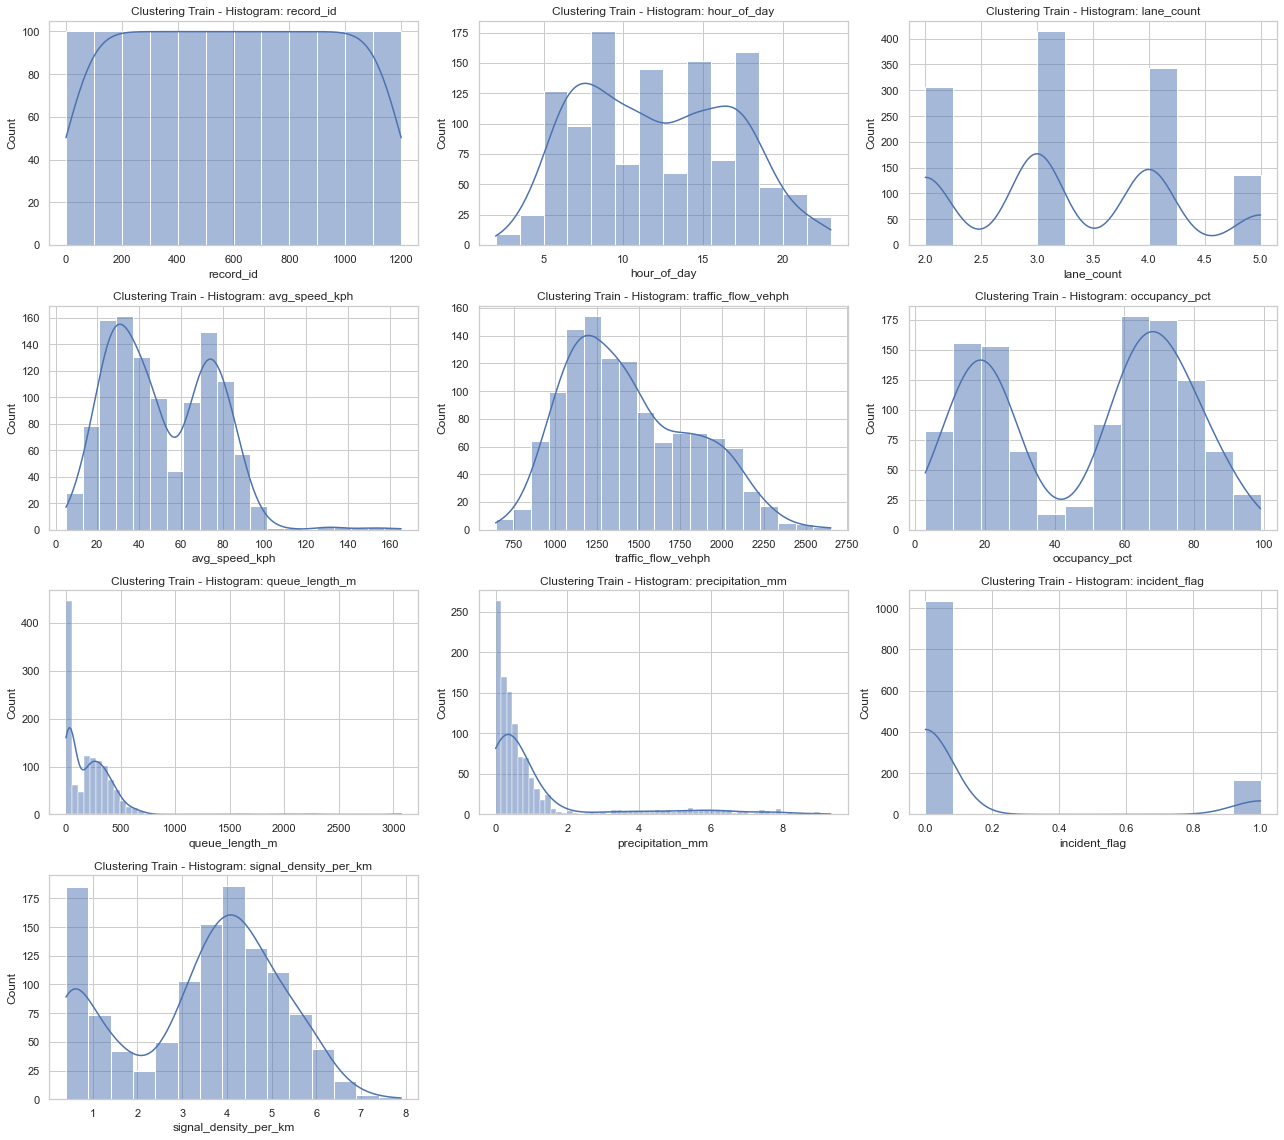

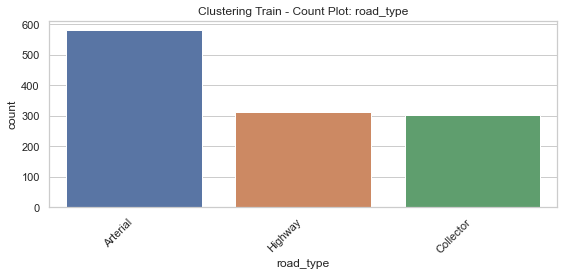

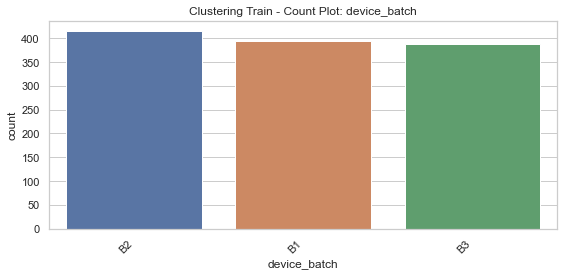

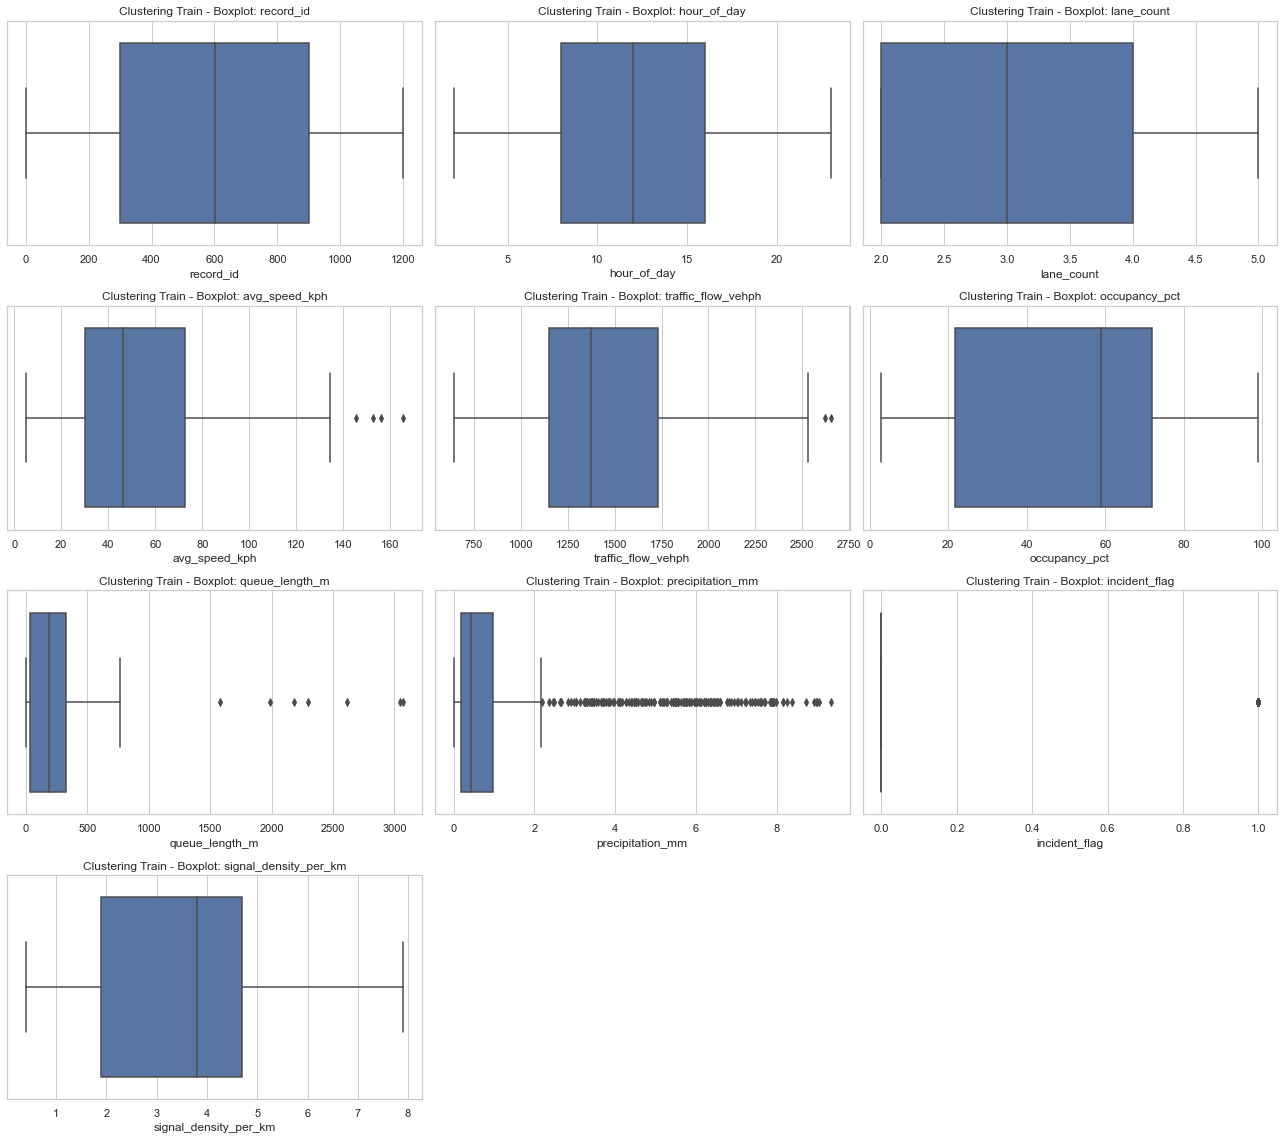

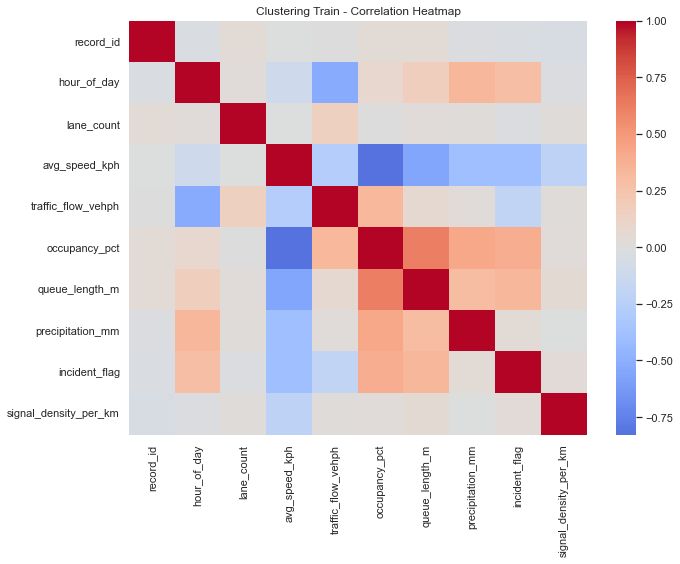

EDA for Classification Train

Summary statistics (numerical):


,count,mean,std,min,25%,50%,75%,max
record_id,1800.0,900.500000,519.759560,1.00,450.7500,900.50,1350.2500,1800.00
hour_of_day,1800.0,11.284444,6.932629,0.00,5.0000,11.00,17.0000,23.00
lane_count,1800.0,2.818889,1.103574,1.00,2.0000,3.00,4.0000,5.00
precipitation_mm,1800.0,1.134156,2.660486,0.00,0.0000,0.06,0.3525,20.80
visibility_km,1710.0,7.966211,2.250031,0.99,6.6700,8.77,9.5875,12.41
incident_flag,1800.0,0.057222,0.232331,0.00,0.0000,0.00,0.0000,1.00
special_event_flag,1800.0,0.012778,0.112346,0.00,0.0000,0.00,0.0000,1.00
signal_density_per_km,1800.0,3.295733,1.855780,0.30,1.6875,3.52,4.6700,7.60
avg_speed_kph,1729.0,54.323193,21.296774,4.00,43.1000,53.20,62.7000,167.90
traffic_flow_vehph,1800.0,968.696222,619.999093,100.00,597.4000,864.60,1194.1500,8243.10



Summary statistics (categorical):


,count,unique,top,freq
road_type,1800,3,Arterial,871
zone_type,1800,4,Urban,687
weather_state,1764,4,Clear,1089
delay_risk_class,1800,4,Low,1419


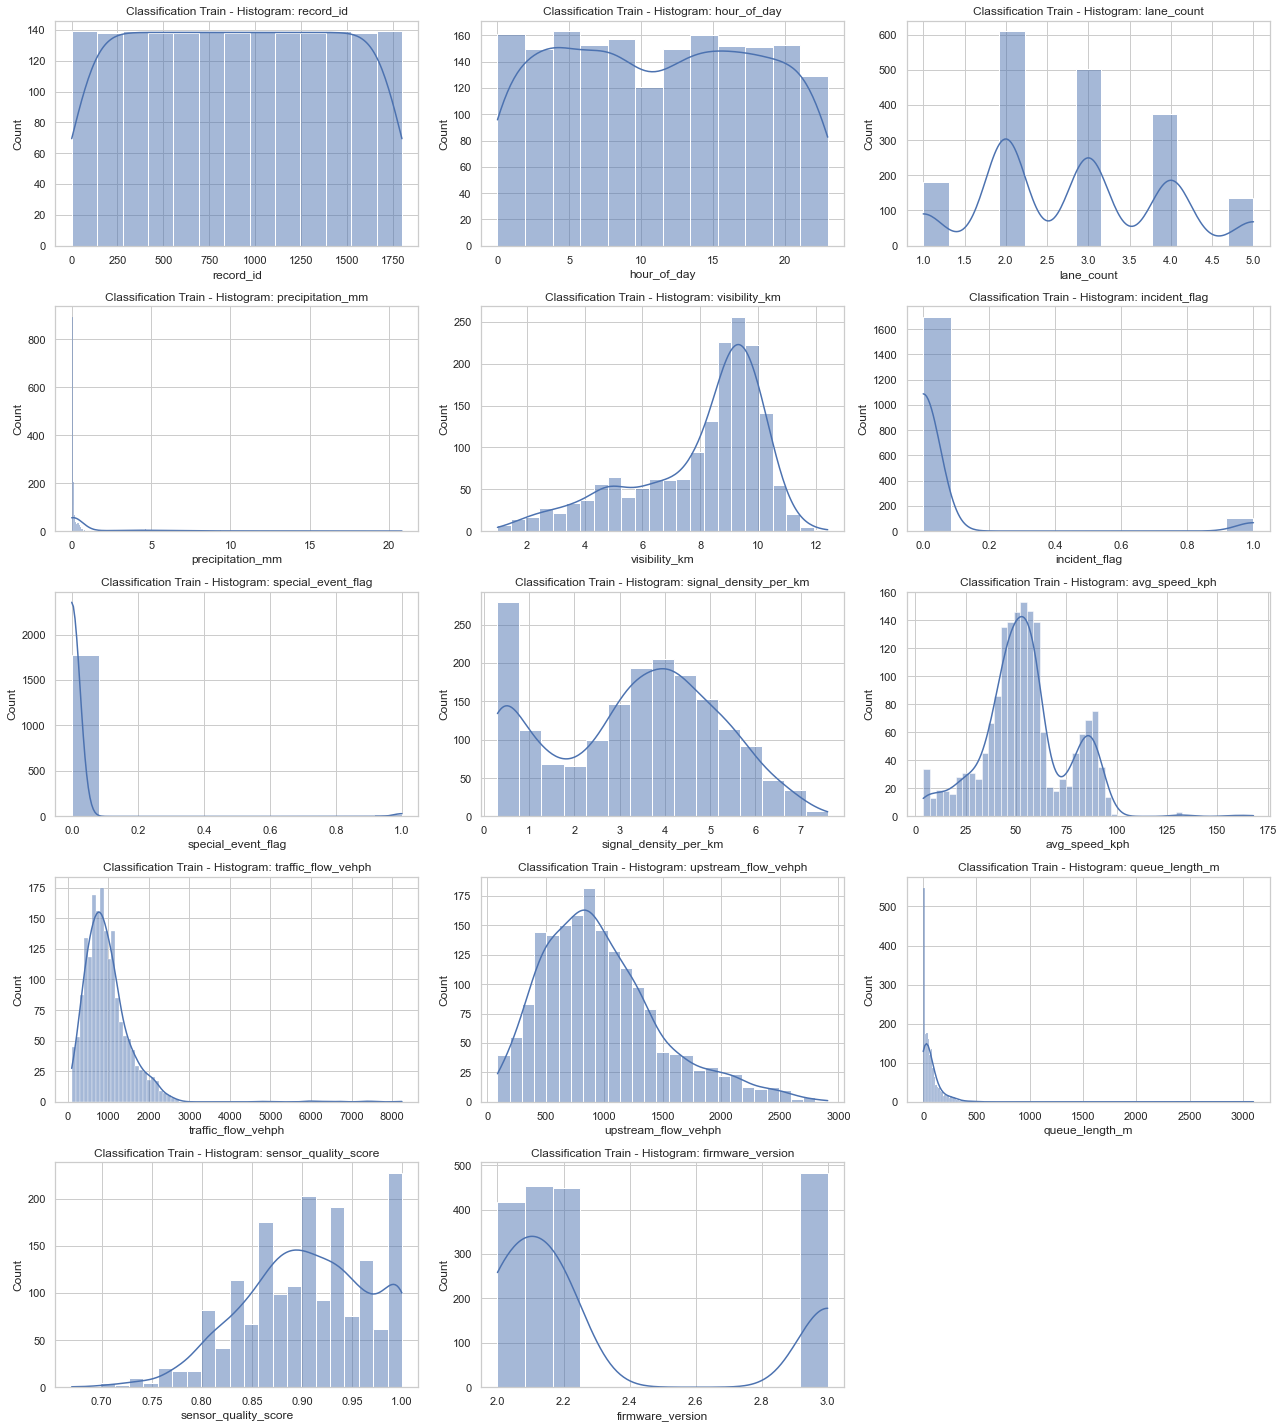

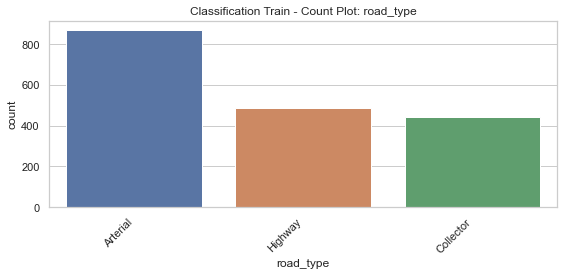

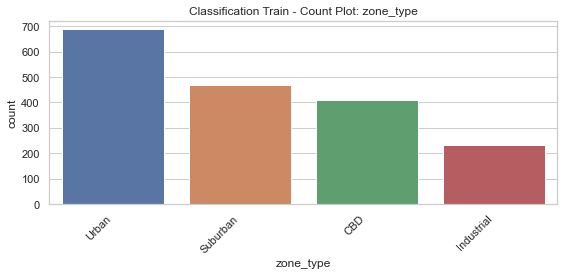

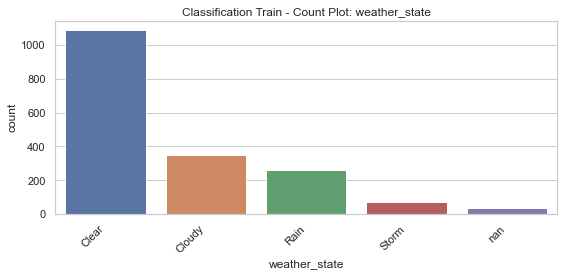

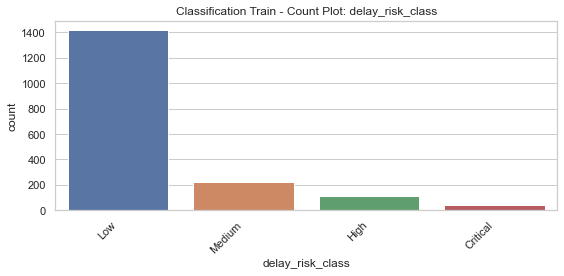

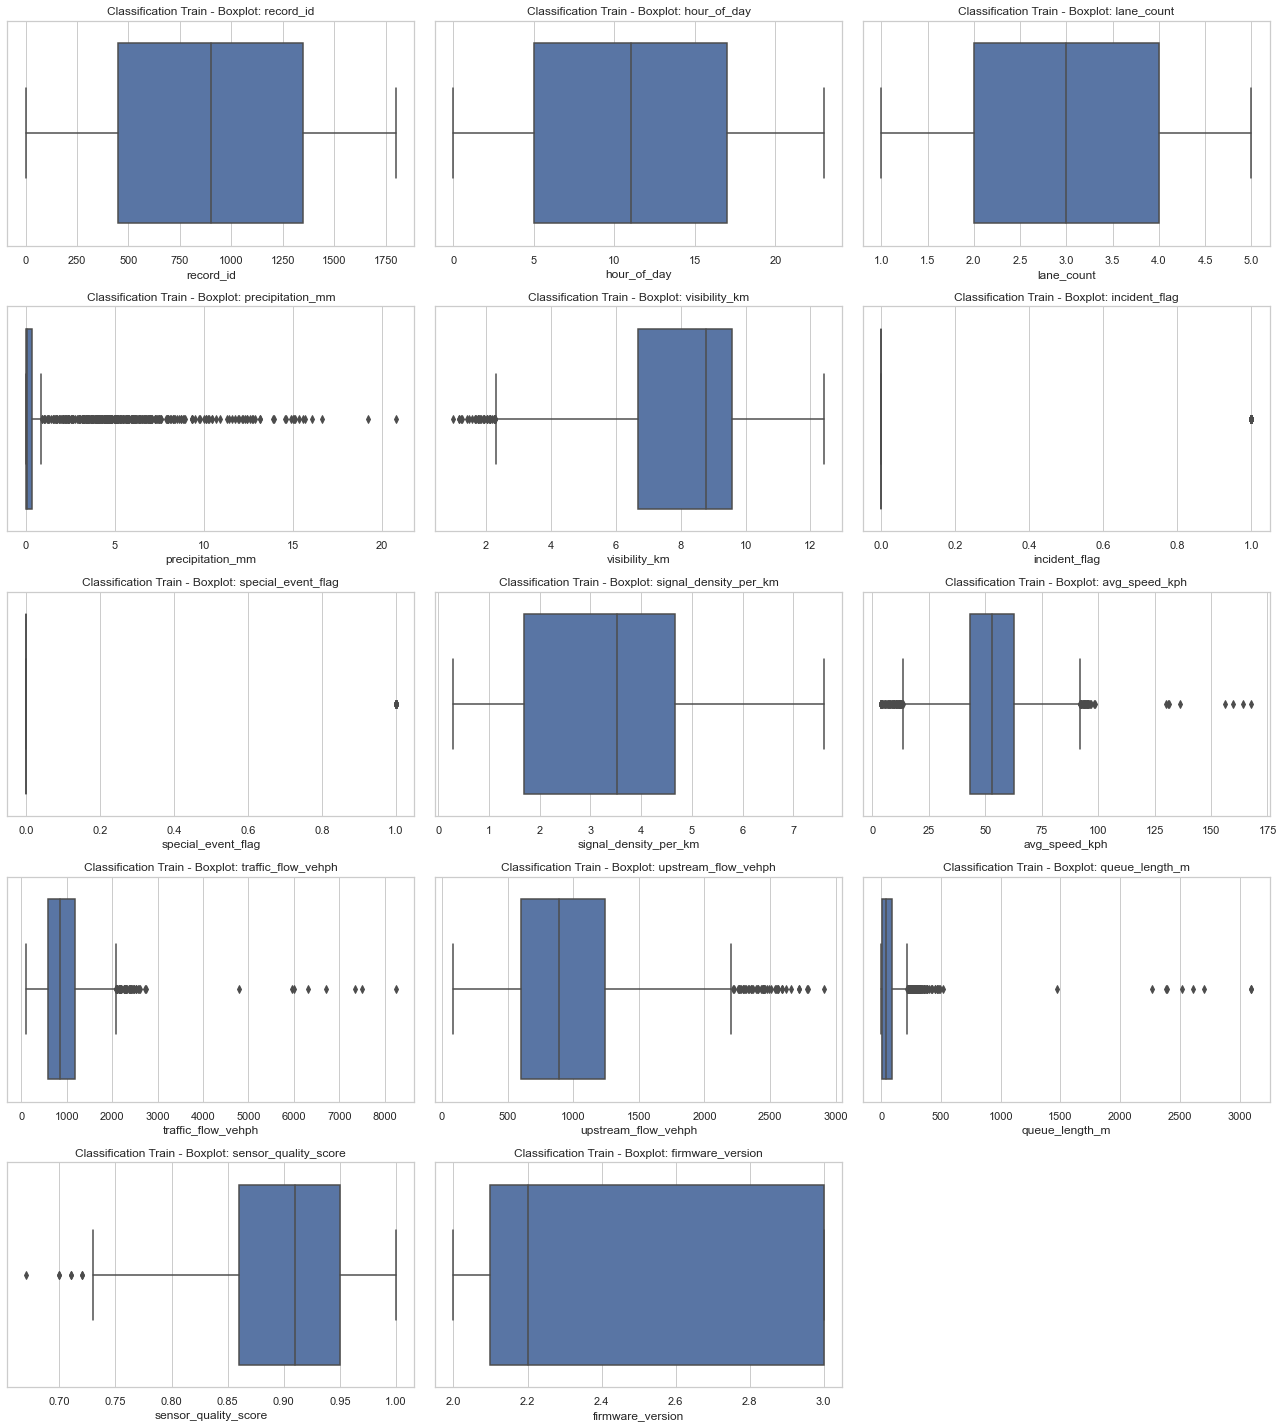

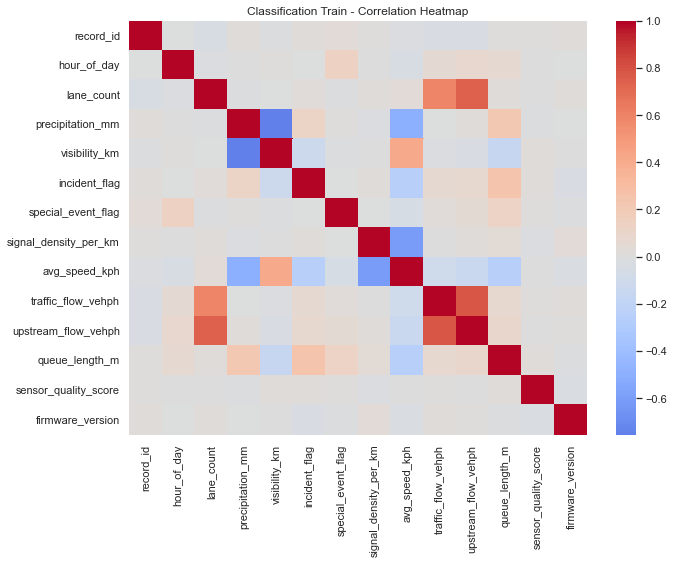

EDA for Regression Train

Summary statistics (numerical):


,count,mean,std,min,25%,50%,75%,max
record_id,1600.0,800.500000,462.024530,1.00,400.7500,800.500,1200.2500,1600.00
hour_of_day,1600.0,11.696875,6.931000,0.00,6.0000,12.000,18.0000,23.00
route_length_km,1600.0,12.010944,5.117273,1.00,8.2775,11.370,15.6900,26.47
distance_km,1600.0,11.790838,5.048826,0.89,8.1475,11.125,15.3600,26.52
precipitation_mm,1520.0,1.271197,2.739192,0.00,0.0000,0.060,0.3950,20.45
signal_density_per_km,1600.0,3.346013,1.772831,0.40,1.6075,3.730,4.6600,7.31
bus_stop_density_per_km,1536.0,2.766009,1.650995,0.10,1.3300,3.050,4.0000,7.09
incident_flag,1600.0,0.076875,0.266476,0.00,0.0000,0.000,0.0000,1.00
demand_index,1600.0,1.204769,0.372877,0.51,0.9000,1.100,1.5200,2.19
avg_speed_kph,1536.0,40.090104,19.587123,6.00,26.6750,36.400,48.5000,158.00



Summary statistics (categorical):


,count,unique,top,freq
road_type,1600,3,Arterial,705
weather_state,1600,4,Clear,917
driver_experience_level,1552,3,Medium,522


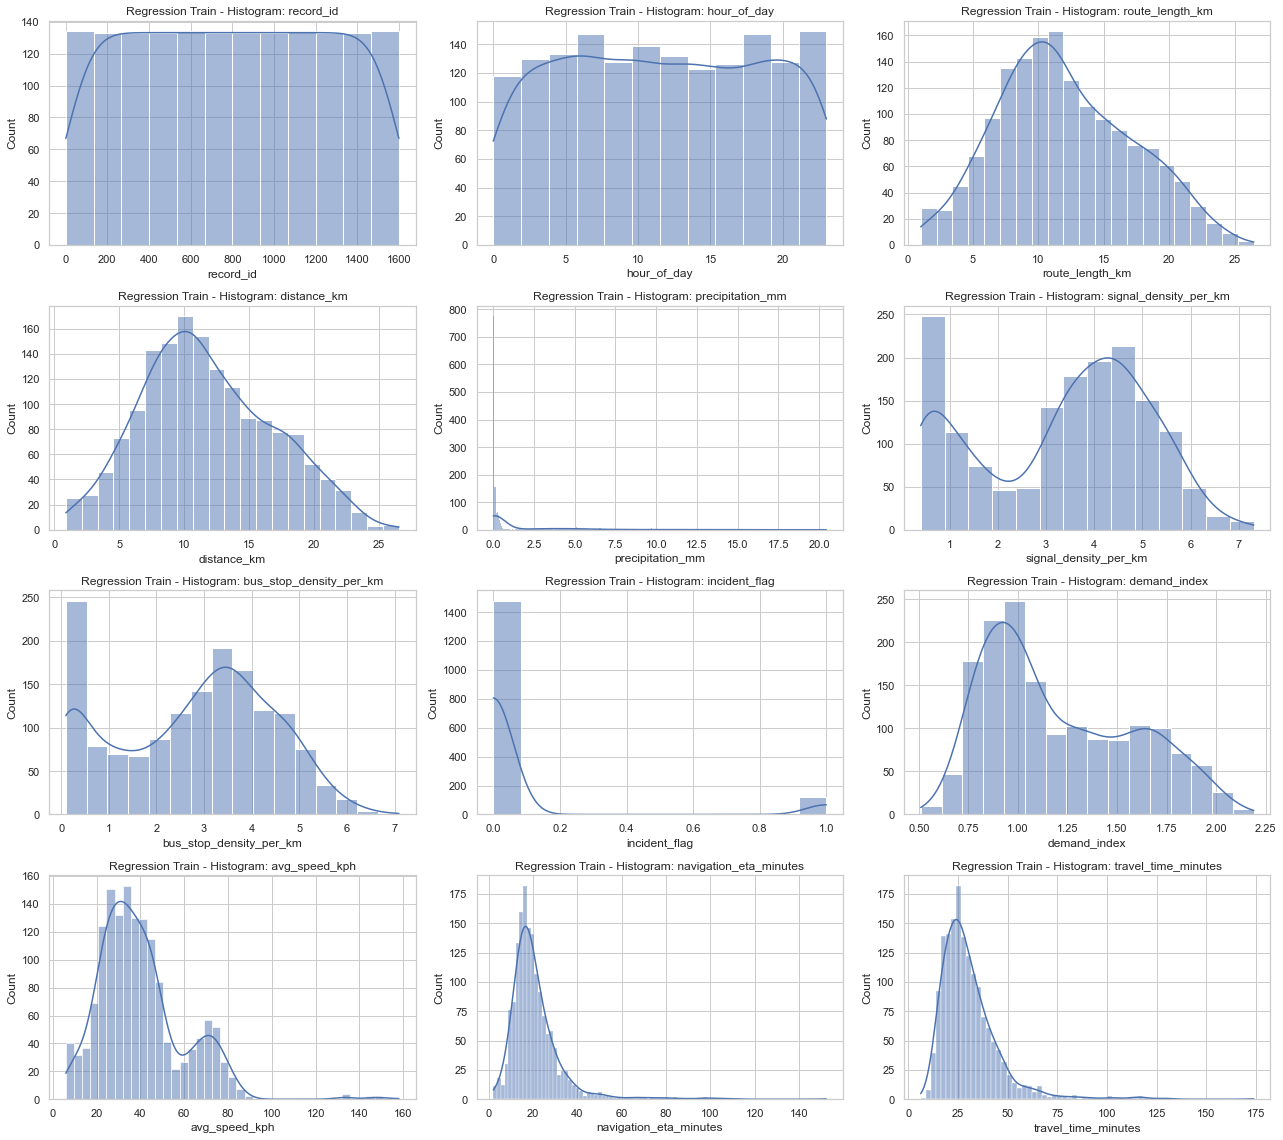

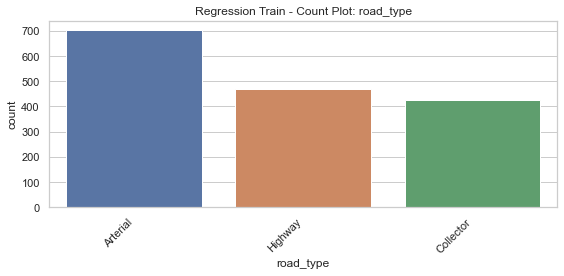

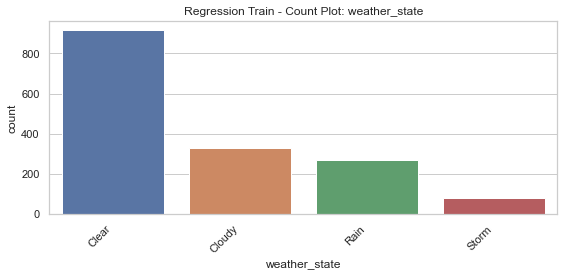

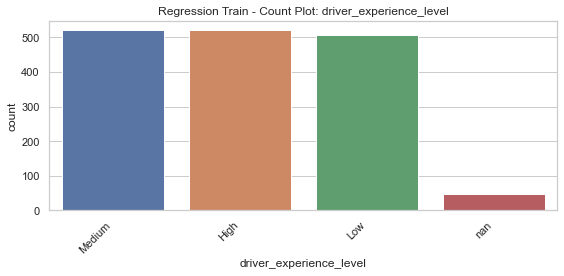

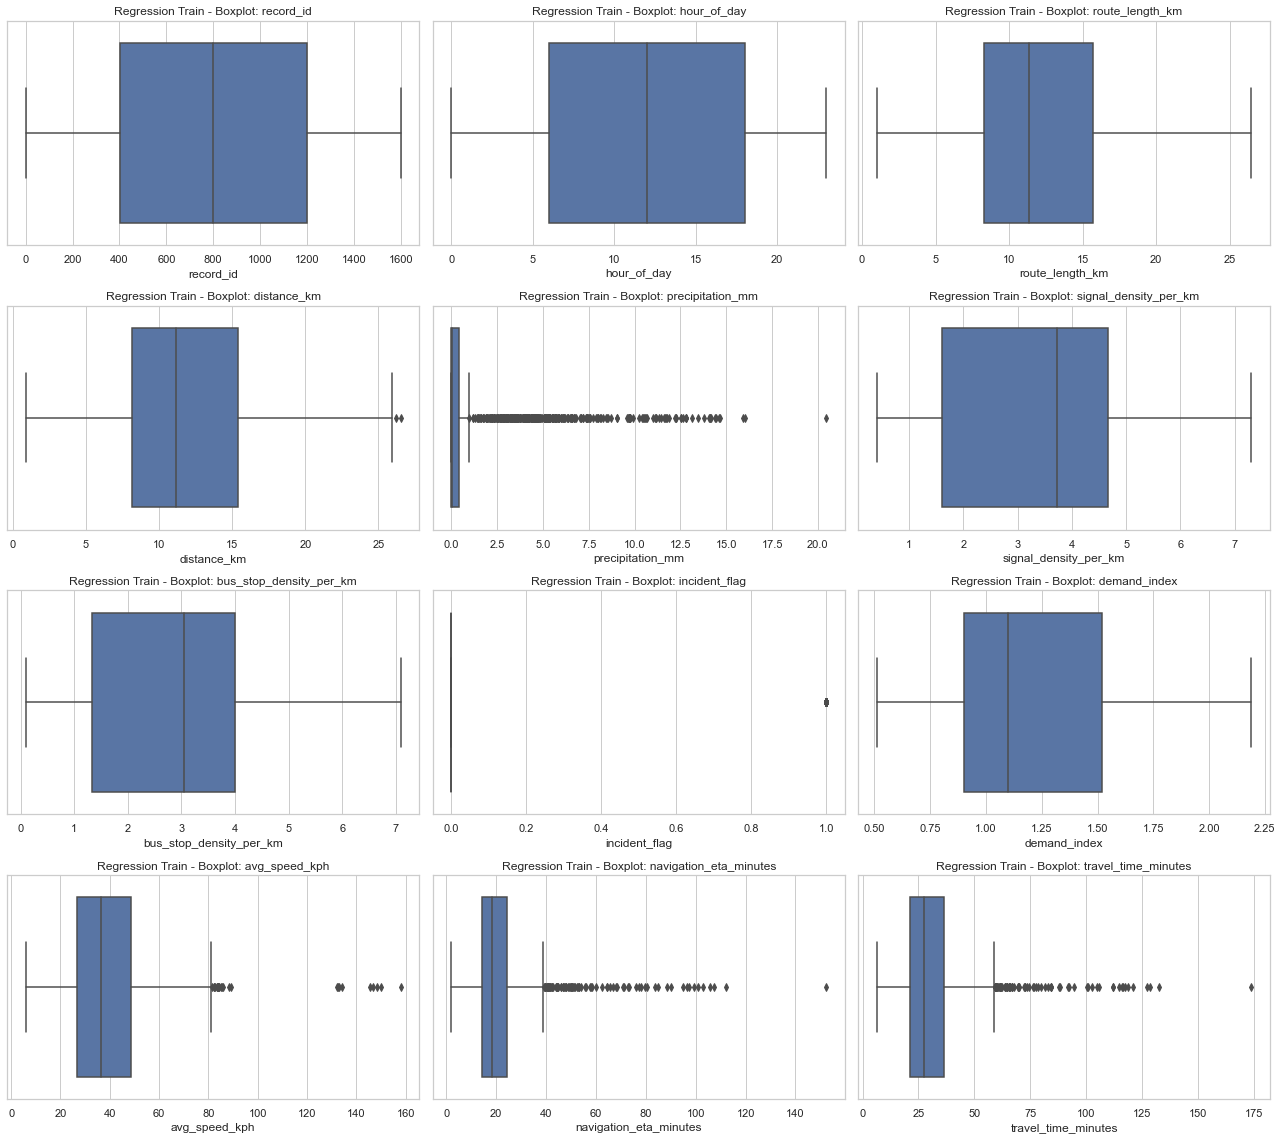

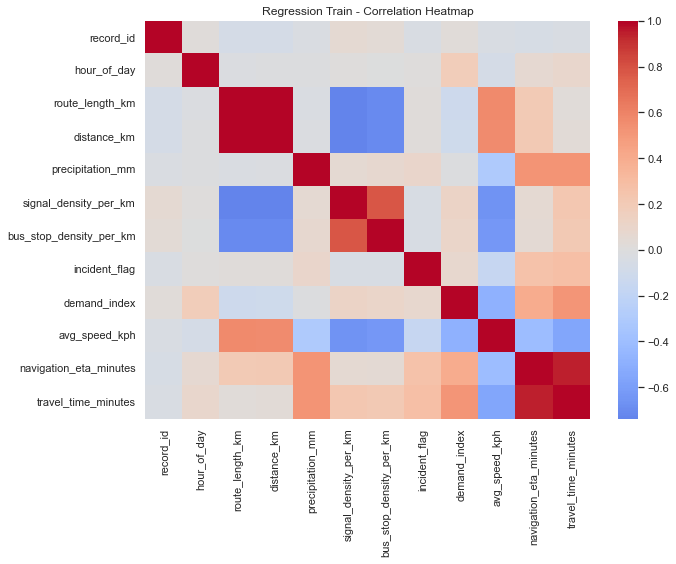

In [24]:

for name, df in training_datasets.items():
    perform_eda(df, name)

### EDA interpretation

The plots above should be interpreted with the following transportation context in mind:

- **Histograms** reveal whether variables are approximately symmetric or heavily skewed. Traffic measures such as travel time, queue length, and delay are often right-skewed.
- **Count plots** highlight category imbalance, which matters for classification and one-hot encoding.
- **Boxplots** expose extreme observations. In transportation, these may represent genuine peak-hour congestion, incidents, or faulty sensor readings.
- **Heatmaps** reveal variable dependency. Strong dependence is common in flow-speed-density relationships, but it can create redundancy in some models.

## 1.3 Missing Value Analysis

Missing values are common in transportation data due to:
- sensor outages,
- communication loss,
- manual recording errors,
- unavailable contextual information.

Ignoring missingness can distort traffic modeling, reduce sample size, and bias estimates. Therefore, we quantify missingness before deciding how to impute it.

In [25]:

def missing_value_report(df):
    """Return a missing-value report with counts and percentages."""
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": (df.isna().sum() / len(df)) * 100
    }).sort_values(by="missing_percentage", ascending=False)
    return report[report["missing_count"] > 0]


def plot_missing_data(df, title="Missing Data Heatmap"):
    plt.figure(figsize=(12, 5))
    sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
    plt.title(title)
    plt.tight_layout()
    plt.show()

Missing value analysis for Clustering Train


,missing_count,missing_percentage
precipitation_mm,72,6.0
avg_speed_kph,60,5.0
occupancy_pct,48,4.0


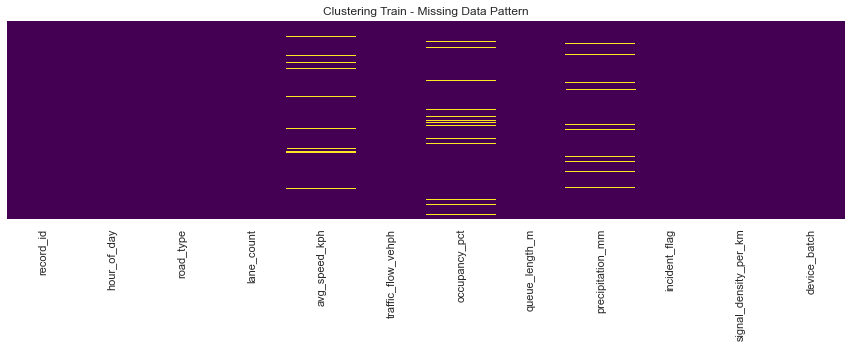

Missing value analysis for Classification Train


,missing_count,missing_percentage
visibility_km,90,5.000000
avg_speed_kph,71,3.944444
sensor_quality_score,54,3.000000
weather_state,36,2.000000


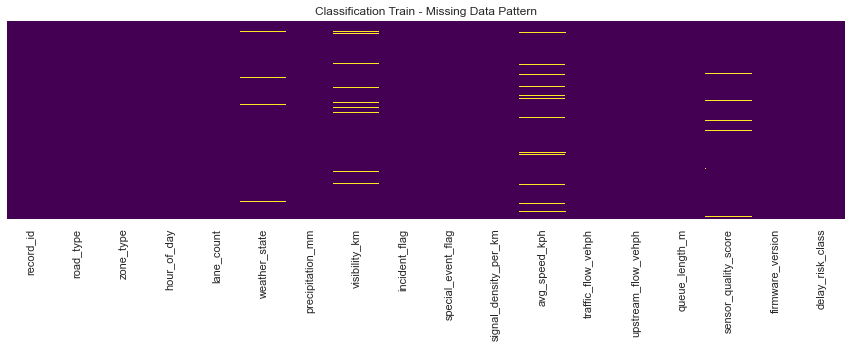

Missing value analysis for Regression Train


,missing_count,missing_percentage
precipitation_mm,80,5.0
bus_stop_density_per_km,64,4.0
avg_speed_kph,64,4.0
driver_experience_level,48,3.0


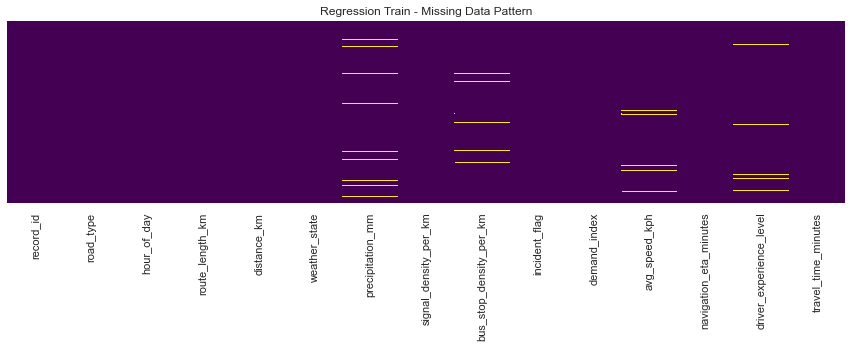

In [26]:

for name, df in training_datasets.items():
    print("=" * 100)
    print(f"Missing value analysis for {name}")
    report = missing_value_report(df)
    if report.empty:
        print("No missing values detected.")
    else:
        display(report)
    plot_missing_data(df, title=f"{name} - Missing Data Pattern")

### Why missing values matter in traffic modeling

In transportation systems, missing values are not merely a technical nuisance. They may correspond to:
- malfunctioning loop detectors,
- missing weather/event context,
- interrupted telemetry,
- manual data recording gaps.

For modeling:
- **dropping rows** can waste valuable operational observations,
- **mean imputation** is sensitive to skew and outliers,
- **median imputation** is more robust for numeric traffic features,
- **mode imputation** is a simple and stable choice for categorical variables.

These considerations motivate the imputation strategy chosen later.

## 1.4 Outlier Detection

Outliers are especially important in transportation data because extreme values can mean one of two things:

1. **Real rare events** such as incidents, road closures, or severe congestion.
2. **Measurement errors** such as faulty sensors or corrupted records.

We use the **IQR method** because it is non-parametric, easy to interpret, and robust to non-normal distributions. This makes it well suited for operational traffic variables.

In [27]:

def detect_outliers(df):
    """Detect outliers in numeric columns using the IQR rule."""
    numeric_cols, _ = split_feature_types(df)
    results = []

    for col in numeric_cols:
        series = df[col].dropna()
        if series.empty:
            results.append({"column": col, "outlier_count": 0, "outlier_percentage": 0.0})
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        mask = (series < lower) | (series > upper)

        results.append({
            "column": col,
            "outlier_count": int(mask.sum()),
            "outlier_percentage": round(100 * mask.mean(), 2)
        })

    return pd.DataFrame(results).sort_values(by="outlier_count", ascending=False)


def visualize_outliers_boxplots(df, dataset_name):
    plot_boxplots(df, title_prefix=f"{dataset_name} - Outlier Inspection")

Outlier detection for Clustering Train


,column,outlier_count,outlier_percentage
8,incident_flag,165,13.75
7,precipitation_mm,157,13.92
6,queue_length_m,7,0.58
3,avg_speed_kph,4,0.35
4,traffic_flow_vehph,2,0.17
0,record_id,0,0.00
1,hour_of_day,0,0.00
2,lane_count,0,0.00
5,occupancy_pct,0,0.00
9,signal_density_per_km,0,0.00


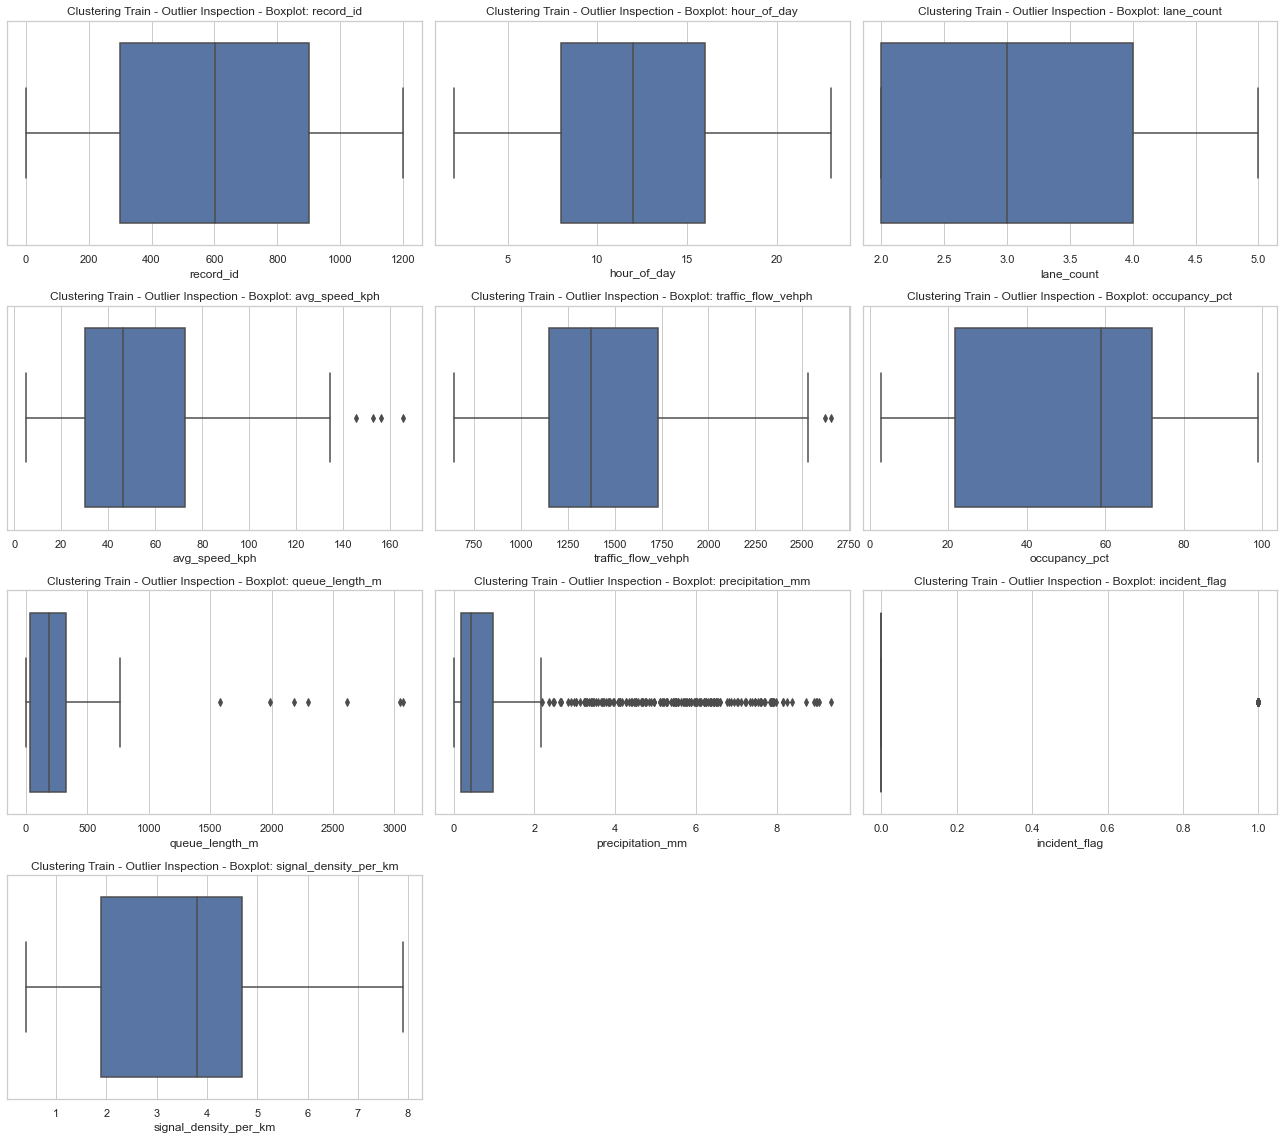

Outlier detection for Classification Train


,column,outlier_count,outlier_percentage
3,precipitation_mm,325,18.06
11,queue_length_m,129,7.17
8,avg_speed_kph,107,6.19
5,incident_flag,103,5.72
9,traffic_flow_vehph,64,3.56
10,upstream_flow_vehph,48,2.67
4,visibility_km,35,2.05
6,special_event_flag,23,1.28
12,sensor_quality_score,7,0.40
0,record_id,0,0.00


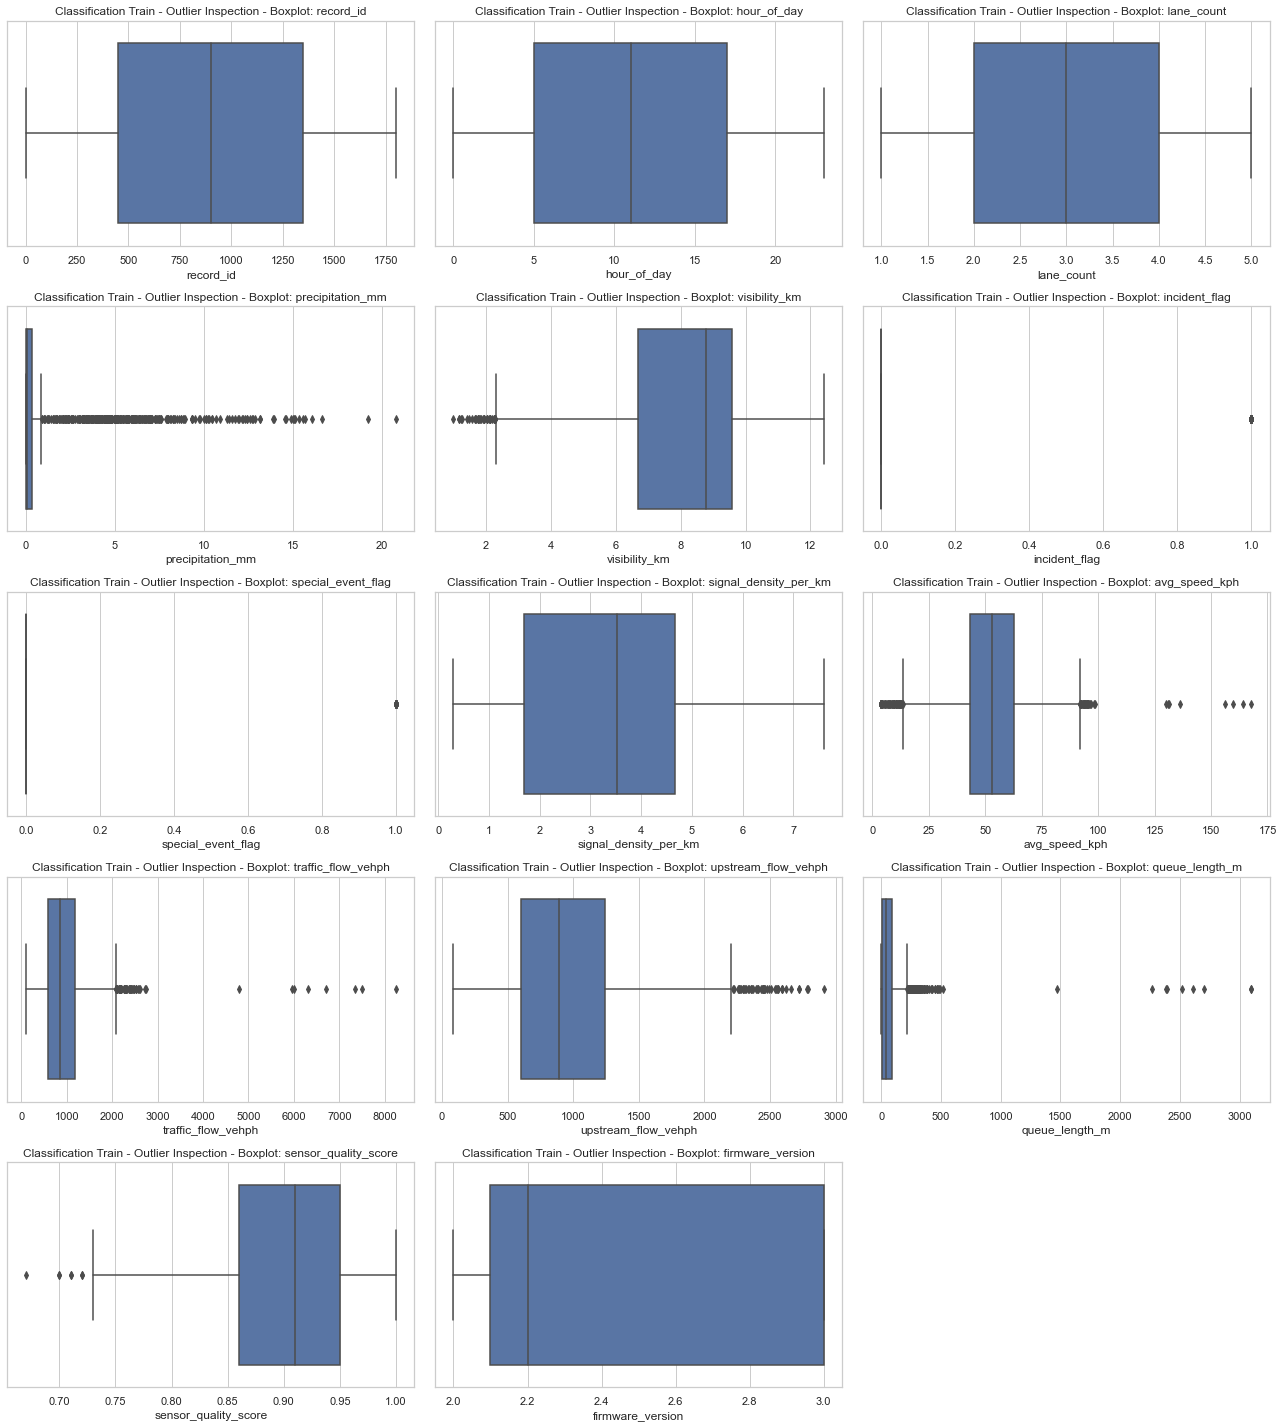

Outlier detection for Regression Train


,column,outlier_count,outlier_percentage
4,precipitation_mm,326,21.45
7,incident_flag,123,7.69
10,navigation_eta_minutes,84,5.25
11,travel_time_minutes,75,4.69
9,avg_speed_kph,25,1.63
3,distance_km,2,0.12
0,record_id,0,0.00
1,hour_of_day,0,0.00
2,route_length_km,0,0.00
5,signal_density_per_km,0,0.00


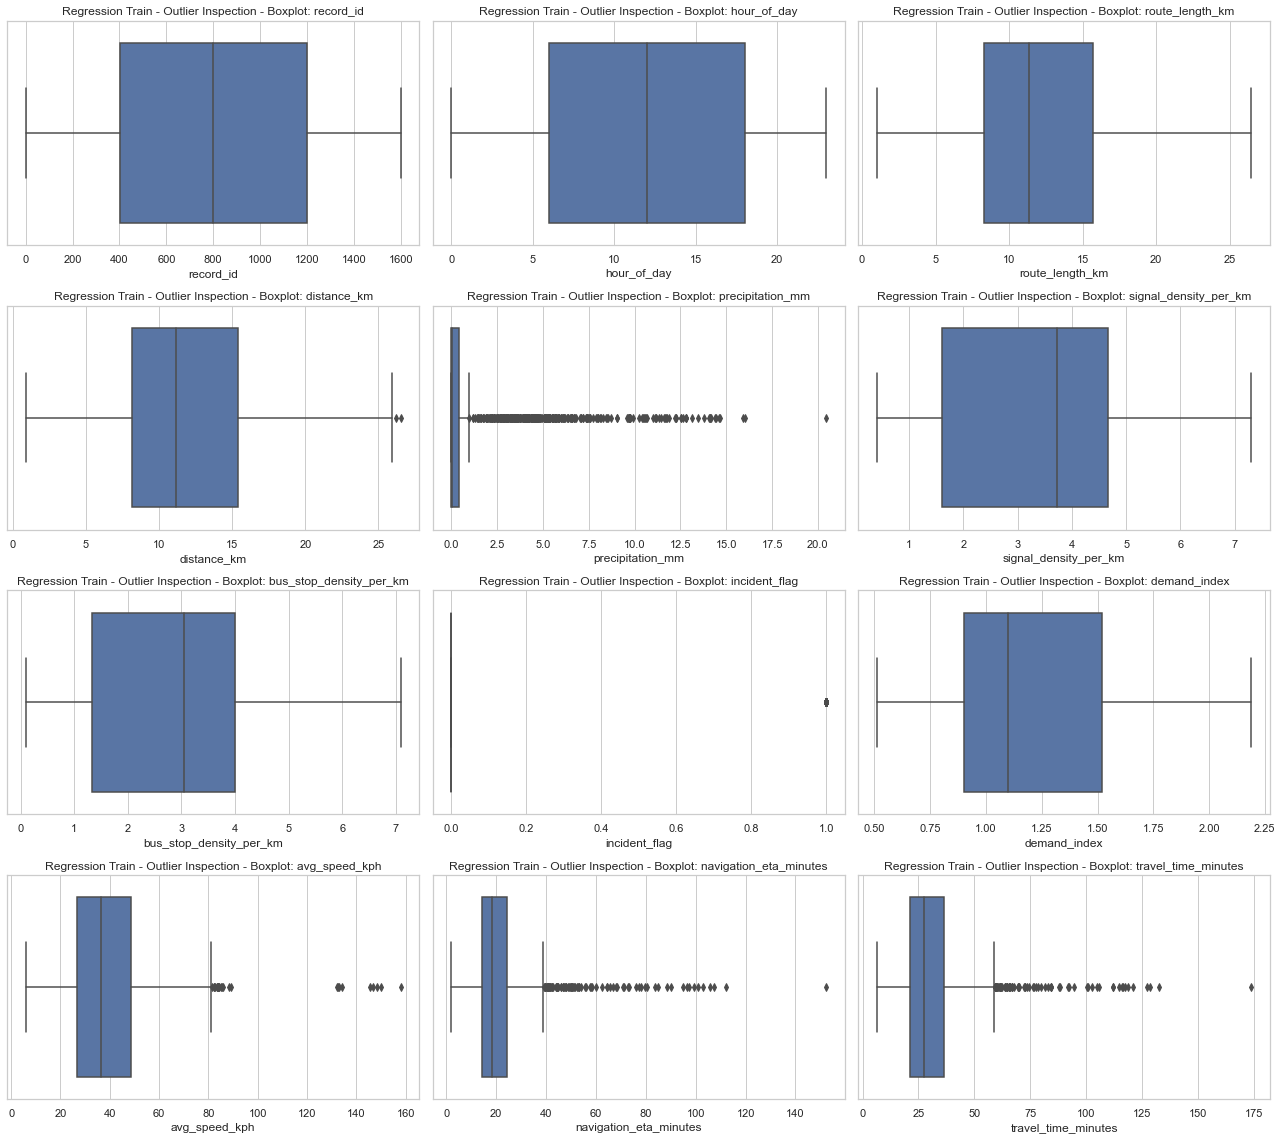

In [28]:

for name, df in training_datasets.items():
    print("=" * 100)
    print(f"Outlier detection for {name}")
    outlier_report = detect_outliers(df)
    display(outlier_report)
    visualize_outliers_boxplots(df, name)

### Why outliers matter in traffic data

Outliers can strongly affect:
- distance-based clustering,
- neural network optimization,
- scale-sensitive algorithms,
- summary statistics used for interpretation.

Because some extreme traffic observations are genuinely meaningful, we do **not** indiscriminately remove them. Instead, we prefer **winsorization (outlier capping)** inside preprocessing, which reduces the influence of extreme values while retaining each observation.

## 1.5 Correlation Analysis

Highly correlated variables are common in transportation systems because many measurements capture related aspects of the same underlying traffic state.

Examples:
- speed and travel time,
- volume and density,
- occupancy and congestion proxy variables.

We identify highly correlated numerical pairs using a threshold of **|correlation| > 0.75**. This is a practical threshold for flagging potential multicollinearity.

In [29]:

def correlation_analysis(df, threshold=0.75):
    """Identify highly correlated variable pairs above a threshold."""
    numeric_cols, _ = split_feature_types(df)
    if len(numeric_cols) < 2:
        return pd.DataFrame(columns=["feature_1", "feature_2", "correlation"])

    corr_matrix = df[numeric_cols].corr().abs()
    upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    high_corr_pairs = []
    for col in upper_triangle.columns:
        for row in upper_triangle.index:
            corr_value = upper_triangle.loc[row, col]
            if pd.notna(corr_value) and corr_value > threshold:
                high_corr_pairs.append({
                    "feature_1": row,
                    "feature_2": col,
                    "correlation": round(corr_value, 4)
                })

    return pd.DataFrame(high_corr_pairs).sort_values(by="correlation", ascending=False)

Correlation analysis for Clustering Train


,feature_1,feature_2,correlation
0,avg_speed_kph,occupancy_pct,0.8271


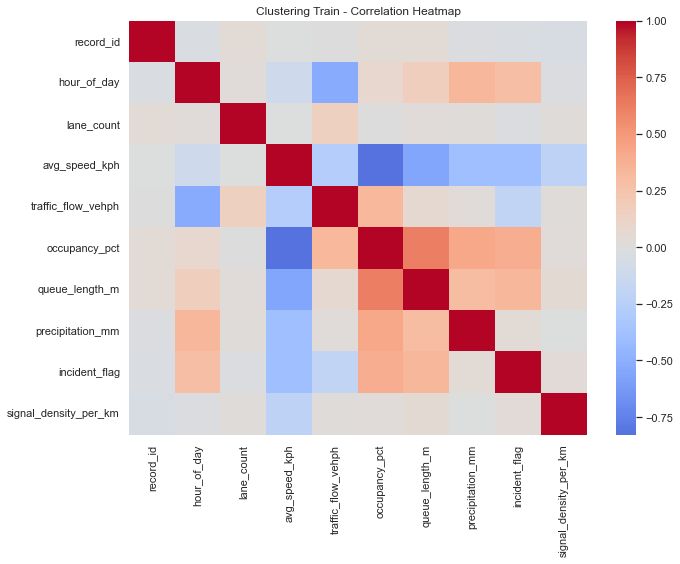

Correlation analysis for Classification Train


,feature_1,feature_2,correlation
1,traffic_flow_vehph,upstream_flow_vehph,0.7807
0,precipitation_mm,visibility_km,0.7549


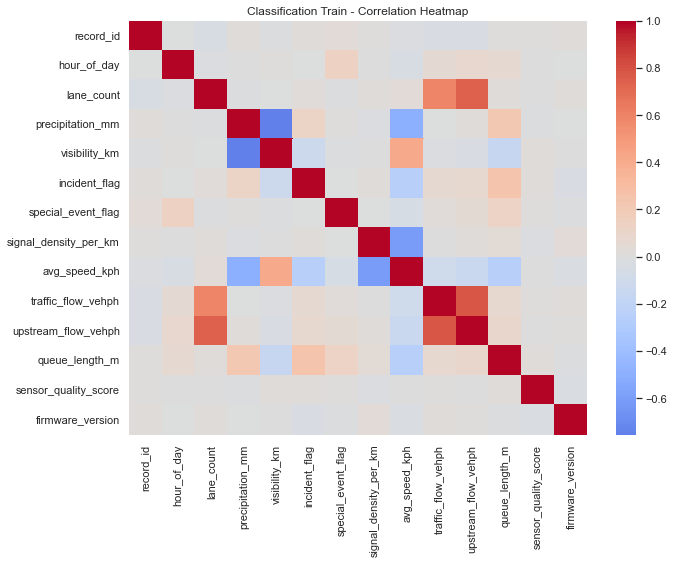

Correlation analysis for Regression Train


,feature_1,feature_2,correlation
0,route_length_km,distance_km,0.9947
2,navigation_eta_minutes,travel_time_minutes,0.9450
1,signal_density_per_km,bus_stop_density_per_km,0.7802


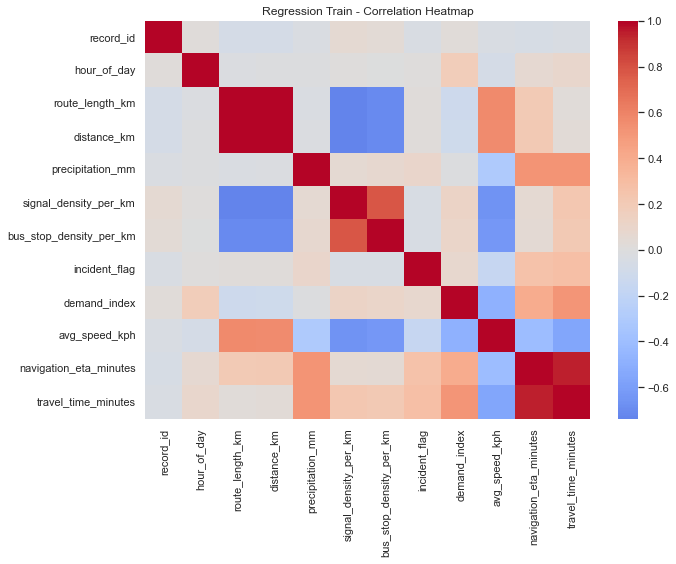

In [30]:

for name, df in training_datasets.items():
    print("=" * 100)
    print(f"Correlation analysis for {name}")
    corr_pairs = correlation_analysis(df, threshold=0.75)
    if corr_pairs.empty:
        print("No highly correlated numeric feature pairs found above the threshold.")
    else:
        display(corr_pairs)
    plot_correlation_heatmap(df, title_prefix=name)

### Why multicollinearity matters

Multicollinearity can:
- inflate the apparent importance of related variables,
- make interpretation less stable,
- reduce efficiency in some linear-style models,
- create redundancy in the feature space.

For this notebook, we **diagnose** correlation carefully, but we do not automatically drop correlated variables. The reason is that tree-based models can often tolerate correlated features better than linear models, and blindly dropping variables may remove useful signal. Instead, we justify any removal conservatively.

## 1.6 Preprocessing Strategy

This section defines the preprocessing decisions and explains why each one is appropriate.

### 1. Dropping ID columns
Identifier columns such as `id`, `record_id`, `trip_id`, or similar are usually not causally meaningful traffic features. They often encode row identity rather than behavior. Keeping them may introduce noise or even accidental leakage. Therefore, likely ID columns will be removed when detected by name patterns.

### 2. Imputation
- **Numeric features:** median imputation is chosen because traffic variables often have skewness and outliers, so the median is more robust than the mean.
- **Categorical features:** mode imputation is selected because it is simple, deterministic, and preserves observed categories.

### 3. One-hot encoding
Categorical variables need numeric representation for most sklearn models. One-hot encoding is preferred because:
- it does not impose artificial ordinal meaning,
- it works well with mixed-model pipelines,
- it integrates naturally with `ColumnTransformer`.

### 4. Scaling choice: StandardScaler vs RobustScaler
- **StandardScaler** is appropriate when variables are roughly well behaved and we want mean-centered, variance-scaled inputs.
- **RobustScaler** is preferred when outliers are present because it uses median and IQR, making it less sensitive to extreme values.

Since transportation data often contains operational spikes and heavy tails, **RobustScaler** is the default choice after winsorization. However, the preprocessing builder is designed so that this choice remains explicit and justified.

### 5. Outlier capping (winsorization)
Rather than deleting observations, we cap extreme numeric values at reasonable quantile limits. This reduces the dominance of extreme values in distance-based and gradient-based algorithms while preserving sample size—an important consideration in transportation analysis.

### 6. Leakage prevention
All preprocessing is implemented inside sklearn-compatible transformers and pipelines, and these are **fit only on training data**. The learned transformations are then applied unchanged to test data.

In [31]:

class IDColumnDropper(BaseEstimator, TransformerMixin):
    """Drop likely identifier columns based on column-name patterns."""

    def __init__(self, extra_patterns=None):
        self.extra_patterns = extra_patterns if extra_patterns is not None else []
        self.columns_to_drop_ = []

    def fit(self, X, y=None):
        patterns = ["id", "uuid", "record", "index", "trip", "sample"]
        patterns.extend(self.extra_patterns)
        self.columns_to_drop_ = [
            col for col in X.columns
            if any(pattern in col.lower() for pattern in patterns)
        ]
        return self

    def transform(self, X):
        return X.drop(columns=self.columns_to_drop_, errors="ignore")


class Winsorizer(BaseEstimator, TransformerMixin):
    """Cap numeric columns based on training quantiles."""

    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            self.lower_bounds_[col] = X_df[col].quantile(self.lower_quantile)
            self.upper_bounds_[col] = X_df[col].quantile(self.upper_quantile)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            lower = self.lower_bounds_.get(col, None)
            upper = self.upper_bounds_.get(col, None)
            X_df[col] = X_df[col].clip(lower=lower, upper=upper)
        return X_df

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler
import numpy as np

# Version-safe OneHotEncoder
def make_onehot():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)  # newer sklearn
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)         # older sklearn

def build_preprocessor(X_train, scaler_type="robust"):
    numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
    categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

    if scaler_type == "robust":
        scaler = RobustScaler()
    else:
        scaler = StandardScaler()

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler)
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_onehot())
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_features),
            ("cat", categorical_pipeline, categorical_features)
        ],
        remainder="drop"
    )

    return preprocessor

## 1.7 Apply Preprocessing

We now apply reusable preprocessing pipelines separately for:
- clustering,
- classification,
- regression.

This separation is good practice because:
- the feature spaces may differ,
- supervised tasks require target separation,
- different tasks may justify different estimators later,
- keeping pipelines task-specific makes the workflow more readable and reproducible.

In [49]:
# -------------------------
# Clustering preprocessing
# -------------------------
# Drop identifier if present
cluster_features_train = df_cluster_train.drop(columns=["record_id"], errors="ignore")
cluster_features_test = df_cluster_test.drop(columns=["record_id"], errors="ignore")

cluster_pipeline = build_preprocessor(cluster_features_train, scaler_type="robust")
X_cluster_train_processed = cluster_pipeline.fit_transform(cluster_features_train)
X_cluster_test_processed = cluster_pipeline.transform(cluster_features_test)

print("Clustering processed train shape:", X_cluster_train_processed.shape)
print("Clustering processed test shape:", X_cluster_test_processed.shape)


# -------------------------
# Classification preprocessing
# -------------------------
class_target_col = "delay_risk_class"

X_class_train = df_class_train.drop(columns=[class_target_col, "record_id"], errors="ignore")
y_class_train = df_class_train[class_target_col]

if class_target_col in df_class_test.columns:
    X_class_test = df_class_test.drop(columns=[class_target_col, "record_id"], errors="ignore")
    y_class_test = df_class_test[class_target_col]
else:
    X_class_test = df_class_test.drop(columns=["record_id"], errors="ignore")
    y_class_test = None

class_pipeline = build_preprocessor(
    X_class_train,
    scaler_type="robust"
)

X_class_train_processed = class_pipeline.fit_transform(X_class_train)
X_class_test_processed = class_pipeline.transform(X_class_test)

print("Classification target column:", class_target_col)
print("Classification processed train shape:", X_class_train_processed.shape)
print("Classification processed test shape:", X_class_test_processed.shape)


# -------------------------
# Regression preprocessing
# -------------------------
reg_target_col = "travel_time_minutes"

X_reg_train = df_reg_train.drop(columns=[reg_target_col, "record_id"], errors="ignore")
y_reg_train = df_reg_train[reg_target_col]

if reg_target_col in df_reg_test.columns:
    X_reg_test = df_reg_test.drop(columns=[reg_target_col, "record_id"], errors="ignore")
    y_reg_test = df_reg_test[reg_target_col]
else:
    X_reg_test = df_reg_test.drop(columns=["record_id"], errors="ignore")
    y_reg_test = None

reg_pipeline = build_preprocessor(
    X_reg_train,
    scaler_type="robust"
)

X_reg_train_processed = reg_pipeline.fit_transform(X_reg_train)
X_reg_test_processed = reg_pipeline.transform(X_reg_test)

print("Regression target column:", reg_target_col)
print("Regression processed train shape:", X_reg_train_processed.shape)
print("Regression processed test shape:", X_reg_test_processed.shape)

Clustering processed train shape: (1200, 15)
Clustering processed test shape: (420, 15)
Classification target column: delay_risk_class
Classification processed train shape: (1800, 24)
Classification processed test shape: (600, 24)
Regression target column: travel_time_minutes
Regression processed train shape: (1600, 20)
Regression processed test shape: (520, 20)


In [50]:
# After preprocessing:
# - Columns increase due to OneHotEncoding
# - Values are scaled → no longer original units
# - Missing values are handled → no NaNs

def show_processed(name, X_train, X_test):
    X_train_df = pd.DataFrame(X_train)
    X_test_df = pd.DataFrame(X_test)
    
    print(f"{name} Train Shape:", X_train_df.shape)
    print(X_train_df.head(), "\n")
    
    print(f"{name} Test Shape:", X_test_df.shape)
    print(X_test_df.head(), "\n")
    print("="*60)

show_processed("Clustering", X_cluster_train_processed, X_cluster_test_processed)
show_processed("Classification", X_class_train_processed, X_class_test_processed)
show_processed("Regression", X_reg_train_processed, X_reg_test_processed)

Clustering Train Shape: (1200, 15)
      0    1         2         3         4         5         6    7         8    9    10   11   12   13   14
0  0.625 -0.5  0.483969 -0.471844 -0.836066 -0.597854 -0.028986  0.0 -0.203936  1.0  0.0  0.0  0.0  0.0  1.0
1  0.125  0.0  0.665457 -0.341047 -0.735656 -0.634986 -0.623188  0.0  0.500894  0.0  1.0  0.0  1.0  0.0  0.0
2  0.875  0.5 -0.612220 -0.209737  0.260246  0.043263  4.043478  0.0  0.368515  0.0  1.0  0.0  1.0  0.0  0.0
3 -1.000  0.0 -0.418633  1.445702  0.157787  0.250383  1.608696  0.0  0.636852  0.0  1.0  0.0  0.0  1.0  0.0
4  1.000  0.5 -0.735632 -0.316705  0.584016  0.203032  0.000000  1.0  0.418605  0.0  1.0  0.0  0.0  0.0  1.0 

Clustering Test Shape: (420, 15)
      0    1         2         3         4         5         6    7         8    9    10   11   12   13   14
0 -0.375  1.0 -0.120992  1.659124  0.223361  0.417646 -0.536232  0.0  0.171735  1.0  0.0  0.0  1.0  0.0  0.0
1 -0.250  0.5 -0.048397  1.488386  0.182377  0.150230 -0.6

In [52]:
def show_info(name, df):
    print(f"{name} Shape: {df.shape}")
    print(df.head())
    print("-" * 50)

show_info("Clustering Train", df_cluster_train)
show_info("Clustering Test", df_cluster_test)

show_info("Classification Train", df_class_train)
show_info("Classification Test", df_class_test)

show_info("Regression Train", df_reg_train)
show_info("Regression Test", df_reg_test)

Clustering Train Shape: (1200, 12)
   record_id  hour_of_day  road_type  lane_count  avg_speed_kph  traffic_flow_vehph  occupancy_pct  queue_length_m  precipitation_mm  \
0          1           17   Arterial           2           66.2              1100.3           18.0            10.9              0.41   
1          2           13  Collector           3           73.7              1176.6           22.9             0.0              0.00   
2          3           19  Collector           4           20.9              1253.2           71.5           199.1              3.22   
3          4            4  Collector           3           28.9              2218.9           66.5           259.9              1.54   
4          5           20  Collector           4           15.8              1190.8           87.3           246.0               NaN   

   incident_flag  signal_density_per_km device_batch  
0              0                   3.23           B3  
1              0                   5.2

# 📘 2. Problem 2 — Traffic Pattern Discovery (Clustering)

## 2.1 Prepare Data

Clustering is an unsupervised problem, so we use the preprocessed clustering dataset directly without a target variable. Because K-Means and hierarchical clustering rely on distances, preprocessing is especially important:
- categorical variables must be encoded,
- numeric variables must be scaled,
- outlier influence should be controlled.

This justifies the leakage-safe preprocessing performed above.

In [53]:

Xc_train = X_cluster_train_processed
Xc_test = X_cluster_test_processed

print("Prepared clustering train matrix shape:", Xc_train.shape)
print("Prepared clustering test matrix shape:", Xc_test.shape)

Prepared clustering train matrix shape: (1200, 15)
Prepared clustering test matrix shape: (420, 15)


## 2.2 K-Means Clustering

We evaluate K-Means because:
- it is a widely used baseline for segmentation,
- it is computationally efficient,
- its cluster centers are easy to interpret.

We use:
- the **Elbow Method** to inspect inertia reduction,
- the **Silhouette Score** to evaluate compactness and separation.

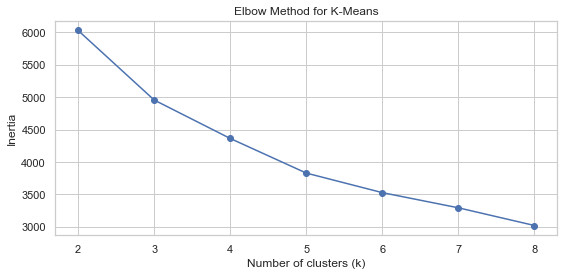

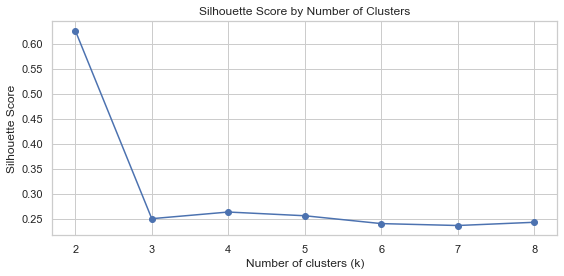

,k,inertia,silhouette_score
0,2,6028.280920,0.626297
1,3,4956.013980,0.250663
2,4,4363.441534,0.263926
3,5,3829.770522,0.256499
4,6,3528.407865,0.240823
5,7,3294.438408,0.237028
6,8,3021.866043,0.243470


In [54]:

k_values = list(range(2, 9))
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(Xc_train)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(Xc_train, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

kmeans_results = pd.DataFrame({
    "k": k_values,
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})
display(kmeans_results)

## 2.3 Hierarchical Clustering

Agglomerative clustering is useful because it does not assume spherical cluster structure in the same way as K-Means and provides a **dendrogram** for visual structure discovery.

For interpretability and computational efficiency, we plot the dendrogram using the preprocessed training matrix.

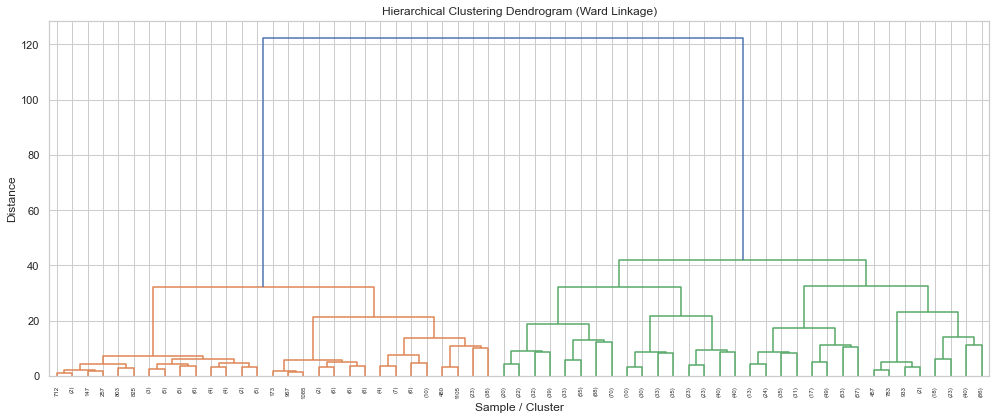

In [55]:

# Dendrogram using Ward linkage
linked = linkage(Xc_train, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(linked, truncate_mode="level", p=5)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Sample / Cluster")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

## 2.4 Optimal Number of Clusters

The final number of clusters should not be selected arbitrarily. We compare:
- inertia reduction from K-Means,
- silhouette quality,
- visual evidence from the dendrogram,
- domain interpretability.

Because the problem explicitly asks for labels:
- **Free Flow**
- **Moderate Traffic**
- **Heavy Congestion**

a three-cluster solution is often practically meaningful. However, we still verify whether this is supported by the unsupervised metrics.

In [56]:

# Choose the best k primarily by silhouette, while keeping domain interpretability in mind
best_k_by_silhouette = kmeans_results.loc[kmeans_results["silhouette_score"].idxmax(), "k"]
print("Best k by silhouette score:", int(best_k_by_silhouette))

# Domain-informed final choice:
final_k = 3
print("Final chosen k (domain-informed and exam-aligned):", final_k)

Best k by silhouette score: 2
Final chosen k (domain-informed and exam-aligned): 3


### Justification of final k

The final choice of **k = 3** is justified by both:
1. the transportation domain interpretation required in the question, and
2. the need for an actionable segmentation into operational traffic states.

If the silhouette-optimal value differs slightly, that does not automatically invalidate `k = 3`. In practice, unsupervised learning often balances statistical structure with decision usefulness.

## 2.5 Cluster Interpretation

We fit the final K-Means model with `k = 3`, examine cluster centers in the processed space, and then assign descriptive labels based on relative traffic intensity.

Because preprocessing transforms the original variables, cluster interpretation is complemented by comparing average values in the **original training data** by assigned cluster where possible.

In [57]:

final_kmeans = KMeans(n_clusters=final_k, random_state=42, n_init=20)
cluster_labels_train = final_kmeans.fit_predict(Xc_train)

agglo = AgglomerativeClustering(n_clusters=final_k, linkage="ward")
agglo_labels_train = agglo.fit_predict(Xc_train)

cluster_centers_processed = pd.DataFrame(final_kmeans.cluster_centers_)
display(cluster_centers_processed.head())

# Add cluster labels to original clustering training dataframe for interpretation
cluster_train_with_labels = df_cluster_train.copy()
cluster_train_with_labels["cluster"] = cluster_labels_train

numeric_cluster_cols = cluster_train_with_labels.select_dtypes(include=[np.number]).columns.tolist()
numeric_cluster_cols = [col for col in numeric_cluster_cols if col != "cluster"]

cluster_profile = cluster_train_with_labels.groupby("cluster")[numeric_cluster_cols].mean()
display(cluster_profile)

# Use average of scaled cluster centers as a simple traffic intensity proxy
center_intensity = cluster_centers_processed.mean(axis=1).sort_values()
ordered_clusters = center_intensity.index.tolist()

cluster_name_map = {
    ordered_clusters[0]: "Free Flow",
    ordered_clusters[1]: "Moderate Congestion",
    ordered_clusters[2]: "Severe Congestion"
}

cluster_train_with_labels["cluster_name"] = cluster_train_with_labels["cluster"].map(cluster_name_map)
display(cluster_train_with_labels[["cluster", "cluster_name"]].drop_duplicates().sort_values("cluster"))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,0.067268,0.135052,0.687365,-0.285020,-0.785001,-0.532918,-0.297774,0.012371,-0.153241,0.503093,0.237113,0.259794,0.344330,0.352577,0.303093
1,0.539931,0.166667,-0.341820,0.084140,0.273096,0.572541,7.726449,0.138889,-0.117621,0.493056,0.250000,0.256944,0.291667,0.284722,0.423611
2,-0.171191,0.112960,-0.275629,0.467877,0.206468,0.475687,0.400010,0.243433,-0.126007,0.469352,0.266200,0.264448,0.325744,0.357268,0.316988


,record_id,hour_of_day,lane_count,avg_speed_kph,traffic_flow_vehph,occupancy_pct,queue_length_m,precipitation_mm,incident_flag,signal_density_per_km
cluster,,,,,,,,,,
0,591.072165,12.538144,3.270103,76.214379,1209.283505,19.353291,29.961856,0.210989,0.012371,3.371691
1,575.409722,16.319444,3.333333,31.352555,1424.633333,72.706522,354.469444,5.761250,0.138889,3.471250
2,614.835377,10.630473,3.225919,34.244301,1648.485989,69.395212,326.037828,0.727921,0.243433,3.447811


,cluster,cluster_name
0,0,Free Flow
2,1,Severe Congestion
3,2,Moderate Congestion


### Interpretation logic

The descriptive labels are assigned based on **relative intensity** rather than arbitrary naming:
- the cluster with the lowest overall center intensity is labeled **Free Flow**,
- the middle cluster is **Moderate Traffic**,
- the highest-intensity cluster is **Heavy Congestion**.

This is a practical interpretation strategy when the dataset does not include a known ground-truth traffic regime label.

## 2.6 Visualization

To visualize clusters, we project the preprocessed feature space to two principal components using PCA. This provides a compact representation of high-dimensional structure while preserving as much variance as possible in two dimensions.

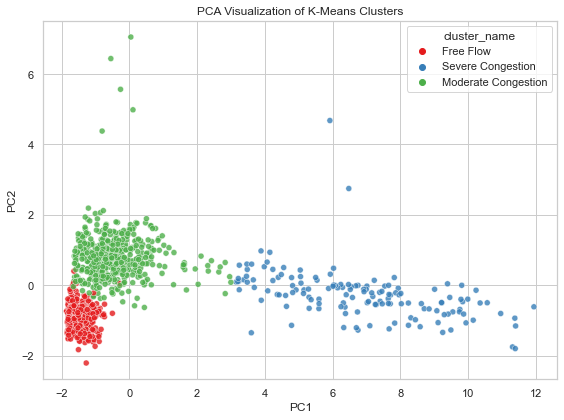

In [58]:

pca = PCA(n_components=2, random_state=42)
Xc_train_pca = pca.fit_transform(Xc_train)

pca_df = pd.DataFrame({
    "PC1": Xc_train_pca[:, 0],
    "PC2": Xc_train_pca[:, 1],
    "cluster": cluster_labels_train,
    "cluster_name": pd.Series(cluster_labels_train).map(cluster_name_map)
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="cluster_name", palette="Set1", alpha=0.8)
plt.title("PCA Visualization of K-Means Clusters")
plt.tight_layout()
plt.show()

## 2.7 Evaluation

For unsupervised evaluation, we report:
- **Silhouette Score**: higher is better,
- **Davies-Bouldin Index**: lower is better.

These metrics assess separation and compactness without requiring class labels.

In [59]:

kmeans_silhouette = silhouette_score(Xc_train, cluster_labels_train)
kmeans_db = davies_bouldin_score(Xc_train, cluster_labels_train)

agglo_silhouette = silhouette_score(Xc_train, agglo_labels_train)
agglo_db = davies_bouldin_score(Xc_train, agglo_labels_train)

clustering_eval = pd.DataFrame({
    "model": ["K-Means", "Agglomerative"],
    "silhouette_score": [kmeans_silhouette, agglo_silhouette],
    "davies_bouldin_index": [kmeans_db, agglo_db]
})
display(clustering_eval)

,model,silhouette_score,davies_bouldin_index
0,K-Means,0.250663,1.384892
1,Agglomerative,0.225670,1.555405


## 2.8 Test Data Application

We apply the trained clustering pipeline to the test dataset and assign cluster labels using the fitted K-Means model. Then we compare train and test cluster distributions.

This helps assess whether the discovered traffic patterns are stable across samples.

,train_proportion,test_proportion
Moderate Congestion,0.475833,0.428571
Free Flow,0.404167,0.447619
Severe Congestion,0.120000,0.123810


<Figure size 576x288 with 0 Axes>

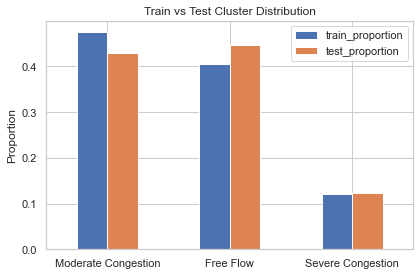

In [60]:

cluster_labels_test = final_kmeans.predict(Xc_test)

train_cluster_dist = pd.Series(cluster_labels_train).map(cluster_name_map).value_counts(normalize=True).rename("train_proportion")
test_cluster_dist = pd.Series(cluster_labels_test).map(cluster_name_map).value_counts(normalize=True).rename("test_proportion")

cluster_distribution_comparison = pd.concat([train_cluster_dist, test_cluster_dist], axis=1).fillna(0)
display(cluster_distribution_comparison)

plt.figure(figsize=(8, 4))
cluster_distribution_comparison.plot(kind="bar")
plt.title("Train vs Test Cluster Distribution")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2.9 Discussion

The comparison of train and test cluster distributions allows us to answer two questions:

### Are traffic patterns consistent?
- If the train and test proportions are similar, the segmented traffic states are likely stable and operationally meaningful.
- If they differ strongly, the test period may reflect a different traffic regime, season, or unusual event profile.

### What does this imply?
- **Consistent patterns** suggest the clustering is capturing reusable traffic states that may support monitoring and planning.
- **Inconsistent patterns** suggest regime shift, non-stationarity, or contextual changes, meaning clustering results should be interpreted cautiously in deployment.

In transportation systems, this matters because traffic states are often time-sensitive and context-dependent.

# 📘 3. Problem 3 — Traffic Condition Classification

## 3.1 Data Preparation

This is a supervised learning task. We:
- separate features and target,
- fit preprocessing on training features only,
- transform test features using the already fitted pipeline.

This procedure prevents data leakage and ensures a fair evaluation.

In [61]:

print("Classification target column selected:", class_target_col)
print("X_class_train shape:", X_class_train.shape)
print("X_class_test shape:", X_class_test.shape)
print("y_class_train shape:", y_class_train.shape)
if y_class_test is not None:
    print("y_class_test shape:", y_class_test.shape)
else:
    print("No target column found in classification test data.")

Classification target column selected: delay_risk_class
X_class_train shape: (1800, 16)
X_class_test shape: (600, 16)
y_class_train shape: (1800,)
y_class_test shape: (600,)


## 3.2 Train Models

We train two models:

### 1. Random Forest
Chosen because:
- it handles nonlinear relationships well,
- it is robust to mixed feature interactions,
- it performs strongly on tabular data,
- it is less sensitive to feature scaling than neural networks.

### 2. Artificial Neural Network (MLPClassifier)
Chosen because:
- it can learn nonlinear decision boundaries,
- it may capture complex relationships if enough signal exists,
- it provides a useful contrast to the tree-based baseline.

Using both models enables a principled comparison between an ensemble method and a neural architecture.

In [62]:

rf_clf = RandomForestClassifier(
    n_estimators=500,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

mlp_clf = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.0005,
    batch_size=64,
    max_iter=800,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42
)

rf_clf.fit(X_class_train_processed, y_class_train)
mlp_clf.fit(X_class_train_processed, y_class_train)

MLPClassifier(alpha=0.001, batch_size=64, early_stopping=True,
              hidden_layer_sizes=(128, 64, 32), learning_rate_init=0.0005,
              max_iter=800, random_state=42)

## 3.3 Model Evaluation

We evaluate using:
- Accuracy
- Precision
- Recall
- F1-score

Because transportation classification can involve class imbalance, relying on accuracy alone is risky. Precision, recall, and F1-score give a more balanced view of performance.

In [63]:

def evaluate_classification_model(model, X, y, model_name="Model"):
    y_pred = model.predict(X)
    results = {
        "model": model_name,
        "accuracy": accuracy_score(y, y_pred),
        "precision_weighted": precision_score(y, y_pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y, y_pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y, y_pred, average="weighted", zero_division=0)
    }
    return results, y_pred


classification_results = []

rf_train_eval, rf_train_pred = evaluate_classification_model(
    rf_clf, X_class_train_processed, y_class_train, "Random Forest (train)"
)
classification_results.append(rf_train_eval)

mlp_train_eval, mlp_train_pred = evaluate_classification_model(
    mlp_clf, X_class_train_processed, y_class_train, "MLPClassifier (train)"
)
classification_results.append(mlp_train_eval)

classification_results_df = pd.DataFrame(classification_results)
display(classification_results_df)

,model,accuracy,precision_weighted,recall_weighted,f1_weighted
0,Random Forest (train),0.986111,0.986106,0.986111,0.985896
1,MLPClassifier (train),0.926111,0.922956,0.926111,0.923313


In [64]:

# If test labels are available, evaluate on test data as well
classification_test_results = []

if y_class_test is not None:
    rf_test_eval, rf_test_pred = evaluate_classification_model(
        rf_clf, X_class_test_processed, y_class_test, "Random Forest (test)"
    )
    mlp_test_eval, mlp_test_pred = evaluate_classification_model(
        mlp_clf, X_class_test_processed, y_class_test, "MLPClassifier (test)"
    )

    classification_test_results.extend([rf_test_eval, mlp_test_eval])
    display(pd.DataFrame(classification_test_results))

    print("Random Forest classification report (test):")
    print(classification_report(y_class_test, rf_test_pred, zero_division=0))

    print("MLPClassifier classification report (test):")
    print(classification_report(y_class_test, mlp_test_pred, zero_division=0))
else:
    print("Classification test labels are unavailable, so only training evaluation is shown.")

,model,accuracy,precision_weighted,recall_weighted,f1_weighted
0,Random Forest (test),0.850,0.843222,0.850,0.845045
1,MLPClassifier (test),0.865,0.860032,0.865,0.859128


Random Forest classification report (test):
              precision    recall  f1-score   support

    Critical       0.88      0.66      0.75        35
        High       0.55      0.53      0.54        59
         Low       0.93      0.98      0.95       411
      Medium       0.62      0.57      0.59        95

    accuracy                           0.85       600
   macro avg       0.75      0.68      0.71       600
weighted avg       0.84      0.85      0.85       600

MLPClassifier classification report (test):
              precision    recall  f1-score   support

    Critical       0.91      0.83      0.87        35
        High       0.68      0.42      0.52        59
         Low       0.94      0.98      0.96       411
      Medium       0.62      0.67      0.64        95

    accuracy                           0.86       600
   macro avg       0.78      0.73      0.75       600
weighted avg       0.86      0.86      0.86       600



## 3.4 Hyperparameter Tuning

We tune **Random Forest** using `RandomizedSearchCV`.

### Why RandomizedSearchCV?
- It is more computationally efficient than exhaustive grid search.
- It explores a wider hyperparameter space under fixed compute.
- For exam and practical settings, it provides a strong trade-off between rigor and runtime.

### Parameters tuned
- `n_estimators`: more trees usually improve stability but increase computation.
- `max_depth`: controls tree complexity and overfitting.
- `min_samples_split`: controls minimum split size.
- `min_samples_leaf`: prevents overly specific leaves.
- `max_features`: controls feature subsampling and diversity.

We use cross-validation on the **training data only**, which preserves proper evaluation discipline.

In [67]:

# Parameter distribution (focused around best values)
mlp_param_dist = {
    "hidden_layer_sizes": [(128, 64), (128, 64, 32)],
    "activation": ["relu"],
    "alpha": [0.0005, 0.001],
    "learning_rate_init": [0.001, 0.0005],
    "batch_size": [32, 64]
}

# Randomized Search
mlp_random_search = RandomizedSearchCV(
    estimator=MLPClassifier(
        solver="adam",
        max_iter=800,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=42
    ),
    param_distributions=mlp_param_dist,
    n_iter=10,
    scoring="f1_weighted",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=1
)

# Fit model
mlp_random_search.fit(X_class_train_processed, y_class_train)

# Results
print("Best ANN parameters:")
print(mlp_random_search.best_params_)

print("\nBest cross-validated score (weighted F1):")
print(mlp_random_search.best_score_)

# Best model
best_mlp_clf = mlp_random_search.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best ANN parameters:
{'learning_rate_init': 0.001, 'hidden_layer_sizes': (128, 64), 'batch_size': 32, 'alpha': 0.001, 'activation': 'relu'}

Best cross-validated score (weighted F1):
0.9021167721946416


In [69]:

cv_results_df = pd.DataFrame(rf_random_search.cv_results_).sort_values(by="rank_test_score")
display(cv_results_df[
    [
        "params",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].head(10))

,params,mean_test_score,std_test_score,rank_test_score
2,"{'n_estimators': 200, 'min_samples_split': 5, ...",0.886399,0.014050,1
3,"{'n_estimators': 300, 'min_samples_split': 2, ...",0.886150,0.011167,2
5,"{'n_estimators': 200, 'min_samples_split': 5, ...",0.885335,0.013648,3
7,"{'n_estimators': 300, 'min_samples_split': 10,...",0.885286,0.017360,4
6,"{'n_estimators': 200, 'min_samples_split': 10,...",0.884409,0.015484,5
1,"{'n_estimators': 200, 'min_samples_split': 2, ...",0.884334,0.011580,6
4,"{'n_estimators': 200, 'min_samples_split': 2, ...",0.882839,0.021323,7
8,"{'n_estimators': 300, 'min_samples_split': 5, ...",0.881478,0.021737,8
0,"{'n_estimators': 200, 'min_samples_split': 2, ...",0.879387,0.018538,9
9,"{'n_estimators': 500, 'min_samples_split': 10,...",0.875391,0.016386,10


### Interpretation of tuning results

The best parameter set should be interpreted as the configuration that produced the strongest **cross-validated weighted F1-score** on training data.

This is preferable to choosing a model based solely on training accuracy because:
- it is more robust to overfitting,
- it accounts for class imbalance more responsibly,
- it estimates generalization more reliably.

## 3.5 Test Data Evaluation

We now evaluate the tuned Random Forest on the test set and compare it with the neural network. This provides the final basis for model selection.

,model,accuracy,precision_weighted,recall_weighted,f1_weighted
0,Best ANN (test),0.856667,0.850972,0.856667,0.849591


Best ANN classification report (test):
              precision    recall  f1-score   support

    Critical       0.96      0.63      0.76        35
        High       0.59      0.64      0.62        59
         Low       0.92      0.99      0.95       411
      Medium       0.66      0.52      0.58        95

    accuracy                           0.86       600
   macro avg       0.78      0.69      0.73       600
weighted avg       0.85      0.86      0.85       600



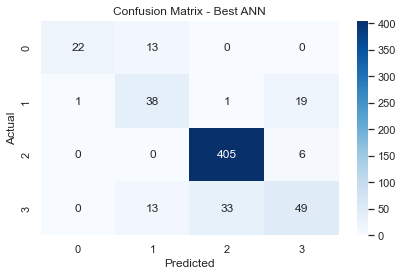

In [71]:

if y_class_test is not None:
    best_mlp_test_eval, best_mlp_test_pred = evaluate_classification_model(
        best_mlp_clf, X_class_test_processed, y_class_test, "Best ANN (test)"
    )
    display(pd.DataFrame([best_mlp_test_eval]))

    print("Best ANN classification report (test):")
    print(classification_report(y_class_test, best_mlp_test_pred, zero_division=0))

    plt.figure(figsize=(6, 4))
    cm = confusion_matrix(y_class_test, best_mlp_test_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title("Confusion Matrix - Best ANN")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
else:
    print("Classification test target is unavailable, so final test evaluation cannot be computed.")

## 3.6 Discussion

### Which model performed best and why?
The best model should be selected based on **test-set performance**, especially weighted F1-score, precision, and recall.

In tabular transportation datasets, **Random Forest often performs better** because:
- it handles heterogeneous tabular features naturally,
- it models nonlinear interactions without heavy tuning,
- it is robust to moderate noise and irrelevant variables.

### Why ANN may underperform or overperform
An ANN may underperform when:
- the dataset is relatively small,
- tabular structure dominates,
- hyperparameter sensitivity is high,
- the signal-to-noise ratio is modest.

An ANN may overperform when:
- relationships are highly nonlinear,
- the dataset is large enough,
- the architecture is well tuned.

### Practical implications for traffic management systems
A strong classifier can support:
- congestion state detection,
- adaptive signal control,
- incident risk screening,
- traveler information systems.

In operational environments, interpretability, latency, and robustness often matter as much as raw accuracy.

# 📘 4. Problem 4 — Traffic Flow Prediction (Regression)

## 4.1 Data Preparation

For regression, we again:
- separate features and target,
- fit preprocessing on training features only,
- transform test features with the same fitted pipeline.

This ensures consistency and prevents leakage into the predictive model.

In [74]:

print("Regression target column selected:", reg_target_col)
print("X_reg_train shape:", X_reg_train.shape)
print("X_reg_test shape:", X_reg_test.shape)
print("y_reg_train shape:", y_reg_train.shape)
if y_reg_test is not None:
    print("y_reg_test shape:", y_reg_test.shape)
else:
    print("No target column found in regression test data.")

Regression target column selected: travel_time_minutes
X_reg_train shape: (1600, 13)
X_reg_test shape: (520, 13)
y_reg_train shape: (1600,)
y_reg_test shape: (520,)


## 4.2 Train Models

We train two regression models:

### 1. Artificial Neural Network (MLPRegressor)
Chosen to capture nonlinear patterns in traffic flow.

### 2. Gradient Boosting Regressor
Chosen because:
- boosting is very strong on structured/tabular data,
- it captures nonlinear effects and interactions,
- it provides feature importance for interpretation.

This comparison is useful because real-time traffic forecasting often depends on balancing predictive power and operational practicality.

In [84]:

mlp_reg = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.0005,
    max_iter=1000,
    random_state=42
)

gbr_reg = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    subsample=0.8,
    random_state=42
)

mlp_reg.fit(X_reg_train_processed, y_reg_train)
gbr_reg.fit(X_reg_train_processed, y_reg_train)

GradientBoostingRegressor(learning_rate=0.03, min_samples_leaf=2,
                          min_samples_split=5, n_estimators=500,
                          random_state=42, subsample=0.8)

## 4.3 Evaluation Metrics

We evaluate using:
- **RMSE**: penalizes large errors strongly,
- **MAE**: gives average absolute error in the original target units,
- **R²**: shows explained variance.

Using all three metrics gives a more complete picture than relying on a single score.

In [85]:

def evaluate_regression_model(model, X, y, model_name="Model"):
    y_pred = model.predict(X)
    rmse = mean_squared_error(y, y_pred, squared=False)
    mae = mean_absolute_error(y, y_pred)
    r2 = r2_score(y, y_pred)

    results = {
        "model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }
    return results, y_pred


regression_train_results = []

mlp_reg_train_eval, mlp_reg_train_pred = evaluate_regression_model(
    mlp_reg, X_reg_train_processed, y_reg_train, "MLPRegressor (train)"
)
gbr_reg_train_eval, gbr_reg_train_pred = evaluate_regression_model(
    gbr_reg, X_reg_train_processed, y_reg_train, "Gradient Boosting (train)"
)

regression_train_results.extend([mlp_reg_train_eval, gbr_reg_train_eval])
display(pd.DataFrame(regression_train_results))

,model,RMSE,MAE,R2
0,MLPRegressor (train),2.502351,1.648654,0.974071
1,Gradient Boosting (train),2.447509,1.726701,0.975195


In [86]:

regression_test_results = []

if y_reg_test is not None:
    mlp_reg_test_eval, mlp_reg_test_pred = evaluate_regression_model(
        mlp_reg, X_reg_test_processed, y_reg_test, "MLPRegressor (test)"
    )
    gbr_reg_test_eval, gbr_reg_test_pred = evaluate_regression_model(
        gbr_reg, X_reg_test_processed, y_reg_test, "Gradient Boosting (test)"
    )

    regression_test_results.extend([mlp_reg_test_eval, gbr_reg_test_eval])
    display(pd.DataFrame(regression_test_results))
else:
    print("Regression test target is unavailable, so final test metrics cannot be computed.")

,model,RMSE,MAE,R2
0,MLPRegressor (test),5.533446,2.726232,0.917260
1,Gradient Boosting (test),5.587389,2.670559,0.915639


## 4.4 Feature Importance

A key advantage of Gradient Boosting is that it provides feature importance estimates. These help us understand which variables contribute most strongly to traffic flow prediction.

Interpretation should remain cautious:
- importance reflects model usage, not necessarily causality,
- correlated features may share or redistribute importance.

In [87]:
print("type(reg_pipeline):", type(reg_pipeline))
print("X_reg_train shape:", X_reg_train.shape)
print("X_reg_train_processed shape:", X_reg_train_processed.shape)
print("Number of GBR importances:", len(gbr_reg.feature_importances_))

if hasattr(reg_pipeline, "named_steps"):
    print("reg_pipeline steps:", reg_pipeline.named_steps.keys())
    preprocessor_only = reg_pipeline.named_steps["preprocessor"]
else:
    preprocessor_only = reg_pipeline

print("type(preprocessor_only):", type(preprocessor_only))
print("named transformers:", preprocessor_only.named_transformers_.keys())

type(reg_pipeline): <class 'sklearn.compose._column_transformer.ColumnTransformer'>
X_reg_train shape: (1600, 13)
X_reg_train_processed shape: (1600, 20)
Number of GBR importances: 20
type(preprocessor_only): <class 'sklearn.compose._column_transformer.ColumnTransformer'>
named transformers: dict_keys(['num', 'cat'])


Recovered feature names: 20
Processed training columns: 20
Gradient Boosting importances: 20


,feature,importance
9,processed_feature_9,0.892211
8,processed_feature_8,0.044960
7,processed_feature_7,0.030065
4,processed_feature_4,0.008633
3,processed_feature_3,0.006885
5,processed_feature_5,0.005667
1,processed_feature_1,0.003700
2,processed_feature_2,0.003287
6,processed_feature_6,0.001988
0,processed_feature_0,0.000895


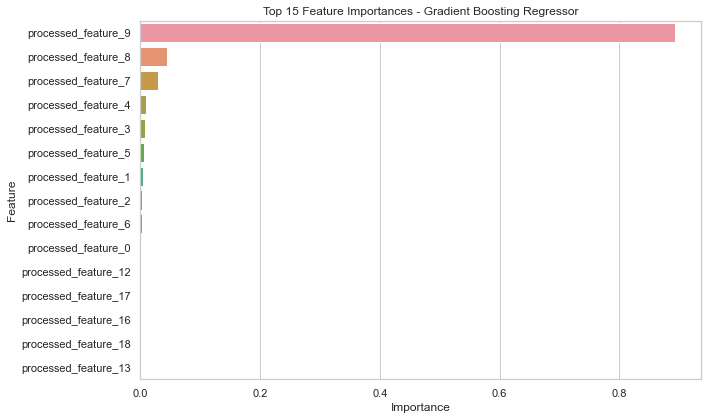

In [88]:
# ============================================================
# Processed feature names for Gradient Boosting model
# ============================================================

# Get the fitted preprocessing step
if hasattr(reg_pipeline, "named_steps"):
    preprocessor_only = reg_pipeline.named_steps["preprocessor"]
else:
    preprocessor_only = reg_pipeline

# Safely recover processed feature names directly from the fitted ColumnTransformer
try:
    feature_names = preprocessor_only.get_feature_names_out()
    feature_names = [name.replace("num__", "").replace("cat__", "") for name in feature_names]
except:
    # Fallback to generic names if feature recovery is not supported
    feature_names = [f"processed_feature_{i}" for i in range(X_reg_train_processed.shape[1])]

print("Recovered feature names:", len(feature_names))
print("Processed training columns:", X_reg_train_processed.shape[1])
print("Gradient Boosting importances:", len(gbr_reg.feature_importances_))

# Final safety check
assert len(feature_names) == len(gbr_reg.feature_importances_), \
    "Feature-name count does not match model importances."

# Create importance dataframe
feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": gbr_reg.feature_importances_
}).sort_values(by="importance", ascending=False)

display(feature_importance_df.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance_df.head(15), x="importance", y="feature")
plt.title("Top 15 Feature Importances - Gradient Boosting Regressor")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [93]:
# Get preprocessor
if hasattr(reg_pipeline, "named_steps"):
    preprocessor = reg_pipeline.named_steps["preprocessor"]
else:
    preprocessor = reg_pipeline

feature_mapping = []

# Numerical features (same names after processing)
if "num" in preprocessor.named_transformers_:
    num_features = numeric_features
    for f in num_features:
        feature_mapping.append((f, f))

# Categorical features (expanded via OneHotEncoder)
if "cat" in preprocessor.named_transformers_:
    cat_pipeline = preprocessor.named_transformers_["cat"]
    ohe = cat_pipeline.named_steps["onehot"]
    
    cat_feature_names = ohe.get_feature_names_out(categorical_features)
    
    for original, encoded in zip(
        np.repeat(categorical_features, [len(ohe.categories_[i]) for i in range(len(categorical_features))]),
        cat_feature_names
    ):
        feature_mapping.append((original, encoded))

# Convert to DataFrame
feature_mapping_df = pd.DataFrame(feature_mapping, columns=["original_feature", "processed_feature"])

display(feature_mapping_df)

,original_feature,processed_feature
0,hour_of_day,hour_of_day
1,route_length_km,route_length_km
2,distance_km,distance_km
3,precipitation_mm,precipitation_mm
4,signal_density_per_km,signal_density_per_km
5,bus_stop_density_per_km,bus_stop_density_per_km
6,avg_speed_kph,avg_speed_kph
7,navigation_eta_minutes,navigation_eta_minutes
8,road_type,road_type_Arterial
9,road_type,road_type_Collector


,original_feature,importance
7,navigation_eta_minutes,0.892211
0,avg_speed_kph,0.044960
2,demand_index,0.030065
11,signal_density_per_km,0.008633
8,precipitation_mm,0.006885
1,bus_stop_density_per_km,0.005667
10,route_length_km,0.003700
3,distance_km,0.003287
6,incident_flag,0.001988
5,hour_of_day,0.000895


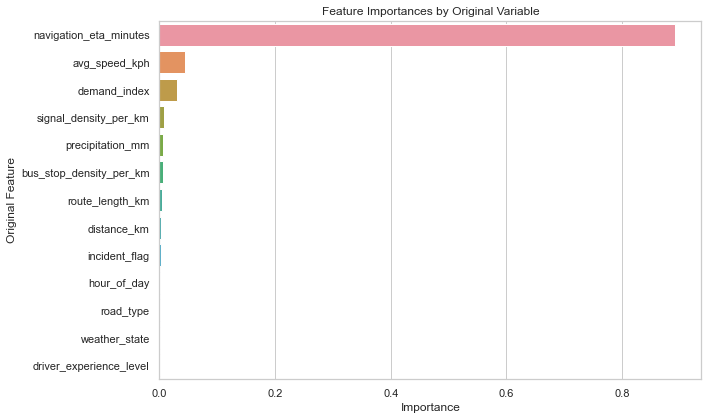

In [96]:
# ============================================================
# Plot feature importance using ORIGINAL feature names
# ============================================================

# Get fitted preprocessor
if hasattr(reg_pipeline, "named_steps"):
    preprocessor = reg_pipeline.named_steps["preprocessor"]
    dropper = reg_pipeline.named_steps["drop_ids"]
    X_reg_train_base = dropper.transform(X_reg_train.copy())
else:
    preprocessor = reg_pipeline
    X_reg_train_base = X_reg_train.copy()

# Original feature groups entering the ColumnTransformer
numeric_features = X_reg_train_base.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_reg_train_base.select_dtypes(exclude=[np.number]).columns.tolist()

# Build processed feature names manually
processed_feature_names = []

# Numeric features stay 1-to-1
processed_feature_names.extend(numeric_features)

# Categorical features expand through OneHotEncoder
if len(categorical_features) > 0:
    cat_pipeline = preprocessor.named_transformers_["cat"]
    ohe = cat_pipeline.named_steps["onehot"]
    cat_feature_names = list(ohe.get_feature_names_out(categorical_features))
    processed_feature_names.extend(cat_feature_names)

# Safety check
if len(processed_feature_names) != len(gbr_reg.feature_importances_):
    raise ValueError(
        f"Feature name count ({len(processed_feature_names)}) does not match "
        f"importance count ({len(gbr_reg.feature_importances_)})"
    )

# Create processed feature importance table
feature_importance_df = pd.DataFrame({
    "processed_feature": processed_feature_names,
    "importance": gbr_reg.feature_importances_
})

# Map processed names back to original names
mapping = []

# Numeric: original -> same
for f in numeric_features:
    mapping.append((f, f))

# Categorical: encoded columns -> original feature
if len(categorical_features) > 0:
    for cat in categorical_features:
        matching_cols = [pf for pf in cat_feature_names if pf.startswith(cat + "_")]
        for col in matching_cols:
            mapping.append((cat, col))

mapping_df = pd.DataFrame(mapping, columns=["original_feature", "processed_feature"])

# Merge and aggregate importance to original features
original_importance = (
    mapping_df.merge(feature_importance_df, on="processed_feature", how="left")
    .groupby("original_feature", as_index=False)["importance"]
    .sum()
    .sort_values(by="importance", ascending=False)
)

display(original_importance)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=original_importance, x="importance", y="original_feature")
plt.title("Feature Importances by Original Variable")
plt.xlabel("Importance")
plt.ylabel("Original Feature")
plt.tight_layout()
plt.show()

## 4.5 Test Data Prediction

We select the better regression model based on available test metrics (or training metrics if test targets are unavailable) and generate predictions on the test set.

In [99]:
# =========================================
# Test Data Prediction for Regression Model
# =========================================

# Choose final regression model

final_reg_model = mlp_reg   # or gbr_reg

# Predict on processed test features
y_reg_test_pred = final_reg_model.predict(X_reg_test_processed)

# Store predictions in a DataFrame
regression_predictions_df = pd.DataFrame({
    "Actual": y_reg_test if y_reg_test is not None else np.nan,
    "Predicted": y_reg_test_pred
})

display(regression_predictions_df.head(10))

# If test targets are available, evaluate performance
if y_reg_test is not None:
    final_reg_test_eval, _ = evaluate_regression_model(
        final_reg_model,
        X_reg_test_processed,
        y_reg_test,
        "Final Regression Model (test)"
    )
    
    display(pd.DataFrame([final_reg_test_eval]))
else:
    print("Regression test target is unavailable, so only predictions are shown.")

,Actual,Predicted
0,110.38,116.158882
1,16.99,15.475353
2,23.45,26.448979
3,21.34,14.848278
4,26.42,30.136889
5,14.82,17.132234
6,41.52,41.269120
7,18.97,19.524217
8,13.04,11.353666
9,26.09,30.310761


,model,RMSE,MAE,R2
0,Final Regression Model (test),5.533446,2.726232,0.91726


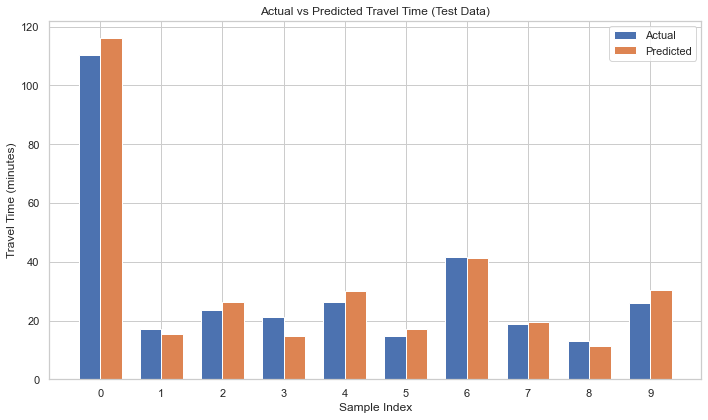

In [100]:
import matplotlib.pyplot as plt
import numpy as np

# Select a subset (first 10 for clarity)
actual = regression_predictions_df["Actual"].head(10)
predicted = regression_predictions_df["Predicted"].head(10)

x = np.arange(len(actual))

plt.figure(figsize=(10, 6))
width = 0.35

plt.bar(x - width/2, actual, width, label="Actual")
plt.bar(x + width/2, predicted, width, label="Predicted")

plt.xlabel("Sample Index")
plt.ylabel("Travel Time (minutes)")
plt.title("Actual vs Predicted Travel Time (Test Data)")
plt.xticks(x)
plt.legend()

plt.tight_layout()
plt.show()